# Proyek Sains Data (PSD): Deteksi Suara Manusia Asli vs Manipulasi AI (*CRISP-DM*)
---
## 0. Import Library
Seluruh *library* Python yang digunakan di sepanjang **6 tahapan CRISP-DM** diimpor satu kali pada *cell* paling atas ini agar kode pada setiap tahapan di bawahnya tetap bersih, modular, dan mudah dibaca.

In [11]:
import os
import time
import warnings
import joblib
import librosa
import librosa.display
import soundfile as sf
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
print('Seluruh library berhasil diimpor dan siap digunakan!')

Seluruh library berhasil diimpor dan siap digunakan!


---
# Tahap 1: *Business Understanding* (Pemahaman Bisnis & Permasalahan)

Tahap pertama dalam metodologi **CRISP-DM (*Cross-Industry Standard Process for Data Mining*)** berfokus pada perumusan masalah di dunia nyata serta penerjemahannya ke dalam tujuan teknis Sains Data.

### 1.1 Latar Belakang Masalah
Kemajuan teknologi kecerdasan buatan generatif (*Generative AI*), khususnya pada *Text-to-Speech* (TTS) dan *AI Voice Cloning*, memungkinkan pembuatan suara tiruan yang sangat menyerupai suara manusia asli hanya dari sampel suara singkat. Di satu sisi teknologi ini bermanfaat, namun di sisi lain menimbulkan ancaman keamanan serius:
1. **Penipuan Suara (*Voice Phishing / Vishing*):** Pelaku kejahatan meniru suara anggota keluarga atau pejabat untuk meminta transfer dana atau informasi rahasia.
2. **Disinformasi & Manipulasi Publik (*Audio Deepfake*):** Pembuatan rekaman pernyataan palsu yang seolah-olah diucapkan oleh tokoh masyarakat.
3. **Ancaman Verifikasi Biometrik Suara:** Sistem autentikasi berbasis suara membutuhkan lapisan deteksi keaslian (*Anti-Spoofing / Liveness Detection*).

### 1.2 Tujuan Bisnis (*Business Objectives*)
Membangun sistem klasifikasi cerdas yang mampu mendeteksi apakah sebuah rekaman suara berasal dari **Manusia Asli (`asli_human`, Label `0`)** atau hasil **Manipulasi/Sintesis AI (`ai_manipulasi`, Label `1`)** secara akurat hanya dari potongan suara singkat berdurasi **5 detik**.

### 1.3 Rumusan Masalah Sains Data (*Data Mining Goals*)
1. **Strategi Segmentasi Audio (30 Detik $\rightarrow$ 5 Detik):** Memotong 200 file audio berdurasi 30 detik (`100 asli_human` dan `100 ai_manipulasi`) menjadi potongan **5 detik** (6 segmen per file) sehingga diperoleh **1.200 sampel segmen** yang kaya dan seimbang.
2. **Ekstraksi & Seleksi Fitur Akustik (*Feature Engineering & Selection*):** Mengekstrak **48 fitur akustik Librosa** dari 4 sudut pandang sinyal (*Time-Domain*, *Frequency/Spectral*, *Pitch $F_0$*, dan *Cepstral/MFCC*), menganalisis fitur mana saja yang paling berpengaruh secara signifikan, serta memilih subset fitur terbaik (*Selected Features*) beserta alasannya.
3. **Pemodelan & Evaluasi (*Modeling & Evaluation*):** Melatih model **Random Forest** dan membandingkannya dengan algoritma klasifikasi lain menggunakan validasi silang (*5-Fold Cross Validation*).

### 1.4 Kriteria Kesuksesan (*Success Criteria*)
- **Akurasi & *F1-Score* pada Data Uji (*Test Set*) $\ge 95\%$** pada segmen berdurasi 5 detik.
- **Pencegahan *Data Leakage*:** Pembagian data *Training* (80%) dan *Testing* (20%) wajib dilakukan pada level **`file_induk`** (bukan mengacak segmen secara bebas), sehingga segmen-segmen dari rekaman yang sama tidak pernah bocor di antara data latih dan data uji.

---
# Tahap 2: *Data Understanding* (Pemahaman & Eksplorasi Data Audio)

Tahap kedua **CRISP-DM** bertujuan memahami struktur, kualitas, serta karakteristik fisik dari sinyal suara sebelum dilakukan pemrosesan lebih lanjut. Tahap ini kita bagi menjadi **4 langkah eksplorasi (*Exploratory Data Analysis / EDA*)** yang terpisah dan terstruktur.

---
## 2.1 Inventarisasi & Validasi Integritas Dataset Audio (200 File Induk)
Sebelum mengekstrak fitur, kita wajib memeriksa seluruh **200 file `.wav`** (`100 asli_human` dan `100 ai_manipulasi`) di dalam folder dataset untuk memvalidasi:
1. **Keseimbangan Kelas (*Class Balance*):** Apakah jumlah sampel kelas `0` (*Manusia Asli*) dan kelas `1` (*Manipulasi AI*) seimbang `50:50`?
2. **Keseragaman Spesifikasi Teknis:** Apakah seluruh file memiliki *Sampling Rate* **`16.000 Hz`** (16.000 titik angka per detik) dan durasi tepat **`30,00 detik`** (`480.000` titik sampel per file)?
3. **Integritas Sinyal:** Apakah ada file yang rusak (*corrupt*), mengandung nilai kosong (`NaN`/`Inf`), atau hening total (*silent audio*)?

1. RINGKASAN JUMLAH DATA & KESEIMBANGAN KELAS (CLASS BALANCE)


,label,kelas,jumlah_file,sr_unik,durasi_min,durasi_max,total_menit,rata2_max_amp,rata2_rms,jumlah_valid
0,0,asli_human,100,[16000],30.0,30.0,50.0,0.2113,0.0240,100
1,1,ai_manipulasi,100,[16000],30.0,30.0,50.0,0.1703,0.0218,100


Total seluruh file diperiksa : 200 file
Total file valid & bersih    : 200 file (File rusak/bermasalah: 0)

Contoh 5 Data Pertama (asli_human) & 5 Data Terakhir (ai_manipulasi):


,nama_file,kelas,label,sr,jumlah_sampel,durasi_detik,max_amplitude,rms_energy,valid
0,audio_001.wav,asli_human,0,16000,480000,30.0,0.1990,0.0216,True
1,audio_002.wav,asli_human,0,16000,480000,30.0,0.2123,0.0213,True
2,audio_003.wav,asli_human,0,16000,480000,30.0,0.2504,0.0212,True
3,audio_004.wav,asli_human,0,16000,480000,30.0,0.1712,0.0216,True
4,audio_005.wav,asli_human,0,16000,480000,30.0,0.1677,0.0206,True
195,audio_096.wav,ai_manipulasi,1,16000,480000,30.0,0.1406,0.0227,True
196,audio_097.wav,ai_manipulasi,1,16000,480000,30.0,0.1489,0.0214,True
197,audio_098.wav,ai_manipulasi,1,16000,480000,30.0,0.1333,0.0215,True
198,audio_099.wav,ai_manipulasi,1,16000,480000,30.0,0.1495,0.0200,True
199,audio_100.wav,ai_manipulasi,1,16000,480000,30.0,0.1576,0.0202,True


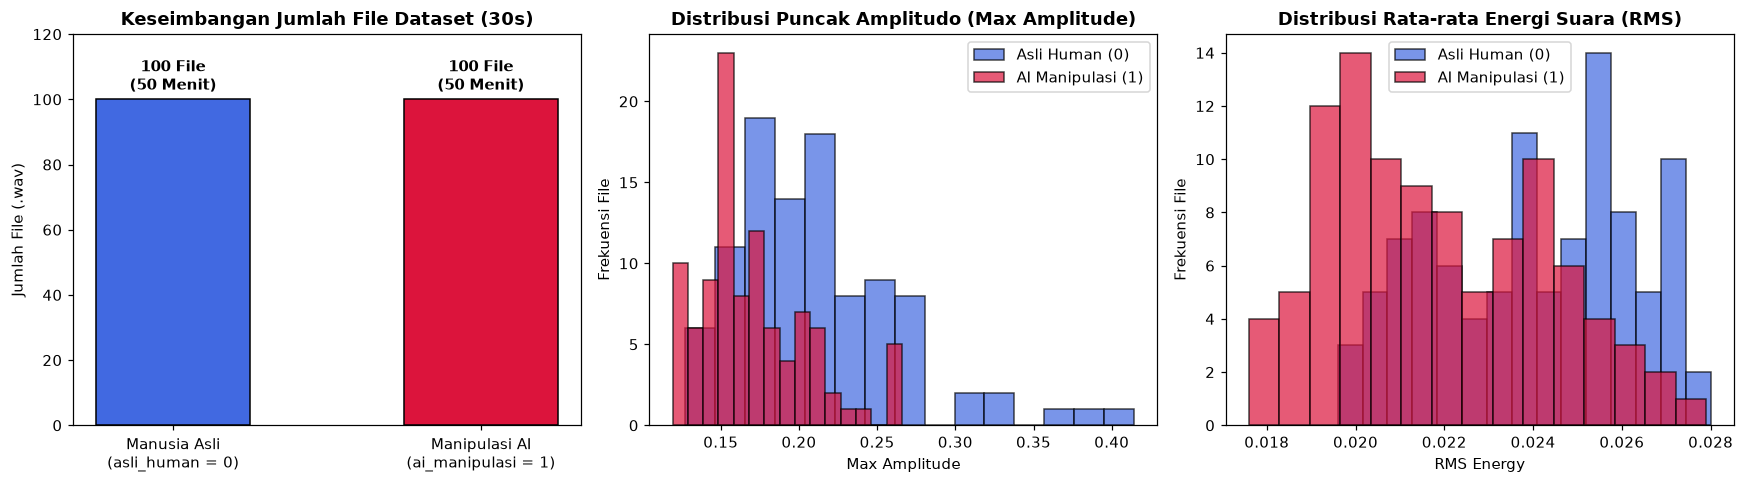

In [15]:
base_dir = '../../data/dataset_audio_kaggle'
kelas_map = {
    'asli_human': 0,
    'ai_manipulasi': 1
}

data_inventaris = []
file_bermasalah = []

for nama_kelas, label_id in kelas_map.items():
    folder_path = os.path.join(base_dir, nama_kelas)
    daftar_wav = sorted([f for f in os.listdir(folder_path) if f.endswith('.wav')])

    for nama_file in daftar_wav:
        full_path = os.path.join(folder_path, nama_file)
        try:
            y, sr_file = sf.read(full_path, dtype='float32')
            jumlah_sampel = len(y)
            durasi_detik  = jumlah_sampel / sr_file
            max_amp       = float(np.max(np.abs(y)))
            rms_val       = float(np.sqrt(np.mean(y**2)))
            ada_nan       = bool(np.isnan(y).any() or np.isinf(y).any())
            is_silent     = bool(max_amp < 1e-4)

            status_valid = (sr_file == 16000) and (abs(durasi_detik - 30.0) < 0.01) and (not ada_nan) and (not is_silent)
            if not status_valid:
                file_bermasalah.append((nama_kelas, nama_file, sr_file, durasi_detik, max_amp))

            data_inventaris.append({
                'nama_file': nama_file,
                'kelas': nama_kelas,
                'label': label_id,
                'sr': sr_file,
                'jumlah_sampel': jumlah_sampel,
                'durasi_detik': round(durasi_detik, 2),
                'max_amplitude': round(max_amp, 4),
                'rms_energy': round(rms_val, 4),
                'valid': status_valid
            })
        except Exception as e:
            file_bermasalah.append((nama_kelas, nama_file, str(e)))

df_inv = pd.DataFrame(data_inventaris)

print('==============================================================')
print('1. RINGKASAN JUMLAH DATA & KESEIMBANGAN KELAS (CLASS BALANCE)')
print('==============================================================')
ringkasan_kelas = df_inv.groupby(['label', 'kelas']).agg(
    jumlah_file=('nama_file', 'count'),
    sr_unik=('sr', lambda x: list(x.unique())),
    durasi_min=('durasi_detik', 'min'),
    durasi_max=('durasi_detik', 'max'),
    total_menit=('durasi_detik', lambda x: round(x.sum() / 60, 1)),
    rata2_max_amp=('max_amplitude', lambda x: round(x.mean(), 4)),
    rata2_rms=('rms_energy', lambda x: round(x.mean(), 4)),
    jumlah_valid=('valid', 'sum')
).reset_index()
display(ringkasan_kelas)

print(f'Total seluruh file diperiksa : {len(df_inv)} file')
print(f'Total file valid & bersih    : {df_inv["valid"].sum()} file (File rusak/bermasalah: {len(file_bermasalah)})')
print('\nContoh 5 Data Pertama (asli_human) & 5 Data Terakhir (ai_manipulasi):')
display(pd.concat([df_inv.head(5), df_inv.tail(5)]))

# Visualisasi Inventaris Dataset
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))


counts = df_inv['kelas'].value_counts()
bars = axes[0].bar(['Manusia Asli\n(asli_human = 0)', 'Manipulasi AI\n(ai_manipulasi = 1)'],
                   [counts['asli_human'], counts['ai_manipulasi']],
                   color=['royalblue', 'crimson'], width=0.5, edgecolor='black')
axes[0].set_title('Keseimbangan Jumlah File Dataset (30s)', fontweight='bold')
axes[0].set_ylabel('Jumlah File (.wav)')
axes[0].set_ylim(0, 120)
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
                 f'{int(bar.get_height())} File\n(50 Menit)', ha='center', fontweight='bold')

axes[1].hist(df_inv[df_inv['label']==0]['max_amplitude'], bins=15, alpha=0.7, label='Asli Human (0)', color='royalblue', edgecolor='black')
axes[1].hist(df_inv[df_inv['label']==1]['max_amplitude'], bins=15, alpha=0.7, label='AI Manipulasi (1)', color='crimson', edgecolor='black')
axes[1].set_title('Distribusi Puncak Amplitudo (Max Amplitude)', fontweight='bold')
axes[1].set_xlabel('Max Amplitude')
axes[1].set_ylabel('Frekuensi File')
axes[1].legend()

axes[2].hist(df_inv[df_inv['label']==0]['rms_energy'], bins=15, alpha=0.7, label='Asli Human (0)', color='royalblue', edgecolor='black')
axes[2].hist(df_inv[df_inv['label']==1]['rms_energy'], bins=15, alpha=0.7, label='AI Manipulasi (1)', color='crimson', edgecolor='black')
axes[2].set_title('Distribusi Rata-rata Energi Suara (RMS)', fontweight='bold')
axes[2].set_xlabel('RMS Energy')
axes[2].set_ylabel('Frekuensi File')
axes[2].legend()

plt.tight_layout()
plt.show()

---
## 2.2 Eksplorasi Sinyal Domain Waktu (*EDA: Waveform, RMS Energy, & Zero Crossing Rate*)
Pada langkah eksplorasi pertama terhadap sinyal suara, kita mengamati perilaku gelombang suara di **Domain Waktu (*Time-Domain*)**:
1. **Gelombang Suara (*Waveform*):** Menampilkan perubahan amplitudo (simpangan tekanan udara) dari waktu ke waktu. Suara manusia asli memiliki dinamika intonasi dan jeda napas yang organik, sedangkan suara AI cenderung memiliki kompresi amplitudo yang sangat seragam.
2. ***Root Mean Square (RMS) Energy*:** Mengukur tingkat kekerasan/energi rata-rata suara pada setiap bingkai waktu (*frame*). Dari kurva RMS pula kita dapat menghitung **`silence_ratio`** (persentase jeda hening saat berbicara).
3. ***Zero Crossing Rate (ZCR)*:** Mengukur seberapa sering gelombang suara melintasi garis amplitudo nol (`0`). Nilai ZCR meningkat tajam saat seseorang mengucapkan huruf konsonan desis (*fricatives* seperti `s`, `f`, `sy`, `c`) atau ketika terdapat derau frekuensi tinggi.

Perbandingan Statistik Fitur Domain Waktu (Potongan 0-5 Detik):


,Metrik Domain Waktu (Segmen 5s),Sampel Manusia Asli (audio_001),Sampel Manipulasi AI (audio_001)
0,RMS Energy Mean,0.0140,0.0231
1,RMS Energy Std,0.0128,0.0096
2,Zero Crossing Rate (ZCR) Mean,0.0670,0.1029
3,Silence Ratio (RMS < 0.01) [%],49.0400,10.8300
4,Skewness (Kemencengan Gelombang),-0.6094,-0.0884
5,Kurtosis (Keruncingan Gelombang),3.6600,1.8139


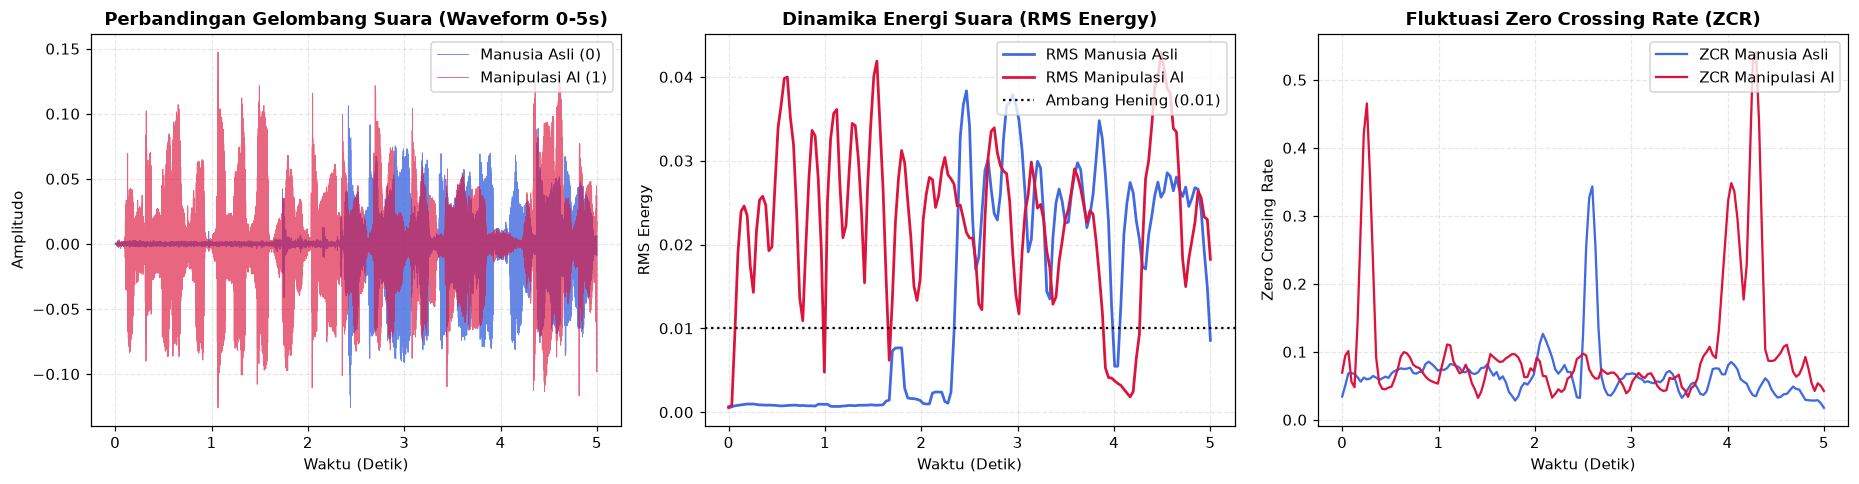

In [16]:
y_asli, sr = sf.read(os.path.join(base_dir, 'asli_human', 'audio_001.wav'), dtype='float32')
y_ai, _    = sf.read(os.path.join(base_dir, 'ai_manipulasi', 'audio_001.wav'), dtype='float32')

# Ambil potongan 5 detik pertama (80.000 sampel) untuk perbandingan detail
y_asli_5s = y_asli[:5 * sr]
y_ai_5s   = y_ai[:5 * sr]
waktu_5s  = np.linspace(0, 5, 5 * sr)

rms_asli = librosa.feature.rms(y=y_asli_5s)[0]
rms_ai   = librosa.feature.rms(y=y_ai_5s)[0]
zcr_asli = librosa.feature.zero_crossing_rate(y=y_asli_5s)[0]
zcr_ai   = librosa.feature.zero_crossing_rate(y=y_ai_5s)[0]
waktu_frame = np.linspace(0, 5, len(rms_asli))

df_eda_time = pd.DataFrame({
    'Metrik Domain Waktu (Segmen 5s)': ['RMS Energy Mean', 'RMS Energy Std', 'Zero Crossing Rate (ZCR) Mean', 'Silence Ratio (RMS < 0.01) [%]', 'Skewness (Kemencengan Gelombang)', 'Kurtosis (Keruncingan Gelombang)'],
    'Sampel Manusia Asli (audio_001)': [round(float(np.mean(rms_asli)), 4), round(float(np.std(rms_asli)), 4), round(float(np.mean(zcr_asli)), 4), round(float(np.mean(rms_asli < 0.01)*100), 2), round(float(stats.skew(y_asli_5s)), 4), round(float(stats.kurtosis(y_asli_5s)), 4)],
    'Sampel Manipulasi AI (audio_001)': [round(float(np.mean(rms_ai)), 4), round(float(np.std(rms_ai)), 4), round(float(np.mean(zcr_ai)), 4), round(float(np.mean(rms_ai < 0.01)*100), 2), round(float(stats.skew(y_ai_5s)), 4), round(float(stats.kurtosis(y_ai_5s)), 4)]
})
print('Perbandingan Statistik Fitur Domain Waktu (Potongan 0-5 Detik):')
display(df_eda_time)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Plot 1: Perbandingan Waveform
axes[0].plot(waktu_5s, y_asli_5s, color='royalblue', alpha=0.8, linewidth=0.6, label='Manusia Asli (0)')
axes[0].plot(waktu_5s, y_ai_5s, color='crimson', alpha=0.65, linewidth=0.6, label='Manipulasi AI (1)')
axes[0].set_title('Perbandingan Gelombang Suara (Waveform 0-5s)', fontweight='bold')
axes[0].set_xlabel('Waktu (Detik)')
axes[0].set_ylabel('Amplitudo')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.3)

# Plot 2: Kurva RMS Energy
axes[1].plot(waktu_frame, rms_asli, color='royalblue', linewidth=1.8, label='RMS Manusia Asli')
axes[1].plot(waktu_frame, rms_ai, color='crimson', linewidth=1.8, label='RMS Manipulasi AI')
axes[1].axhline(0.01, color='black', linestyle=':', label='Ambang Hening (0.01)')
axes[1].set_title('Dinamika Energi Suara (RMS Energy)', fontweight='bold')
axes[1].set_xlabel('Waktu (Detik)')
axes[1].set_ylabel('RMS Energy')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.3)

# Plot 3: Kurva Zero Crossing Rate (ZCR)
axes[2].plot(waktu_frame, zcr_asli, color='royalblue', linewidth=1.5, label='ZCR Manusia Asli')
axes[2].plot(waktu_frame, zcr_ai, color='crimson', linewidth=1.5, label='ZCR Manipulasi AI')
axes[2].set_title('Fluktuasi Zero Crossing Rate (ZCR)', fontweight='bold')
axes[2].set_xlabel('Waktu (Detik)')
axes[2].set_ylabel('Zero Crossing Rate')
axes[2].legend(loc='upper right')
axes[2].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

---
## 2.3 Eksplorasi Sinyal Domain Frekuensi (*EDA: Mel-Spectrogram, Spectral Centroid, & Rolloff*)
Banyak artefak suara sintetis AI tidak terlihat dengan mata telanjang pada gelombang waktu (*waveform*), tetapi sangat jelas terlihat ketika sinyal diubah ke **Domain Frekuensi (*Spectral Domain*)** menggunakan *Short-Time Fourier Transform (STFT)*:
1. ***Mel-Spectrogram*:** Peta distribusi energi suara pada berbagai pita frekuensi (dalam skala *Mel* yang menyesuaikan pendengaran manusia) terhadap waktu.
2. ***Spectral Centroid*:** Titik pusat massa spektrum frekuensi (sering dianalogikan sebagai tingkat "kecerahan/ketajaman" suara dalam satuan `Hz`).
3. ***Spectral Rolloff*:** Batas frekuensi di mana **85%** dari total energi spektrum terkonsentrasi di bawah frekuensi tersebut.
4. ***Spectral Bandwidth, Flatness, & Contrast*:** Mengukur lebar sebaran frekuensi, kemiripan suara dengan *white noise* (*flatness*), serta selisih puncak lembah harmonik (*contrast*).

Perbandingan Statistik Fitur Spektral Frekuensi (Potongan 0-5 Detik):


,Metrik Spektral Frekuensi (0-5 Detik),Sampel Manusia Asli (audio_001),Sampel Manipulasi AI (audio_001)
0,Spectral Centroid Mean (Hz),1185.6800,1656.40000
1,Spectral Bandwidth Mean (Hz),1448.8900,1581.45000
2,Spectral Rolloff Mean (Hz),2306.9300,3159.58000
3,Spectral Flatness Mean,0.0107,0.01396
4,Spectral Contrast Mean (dB),18.1000,21.37000


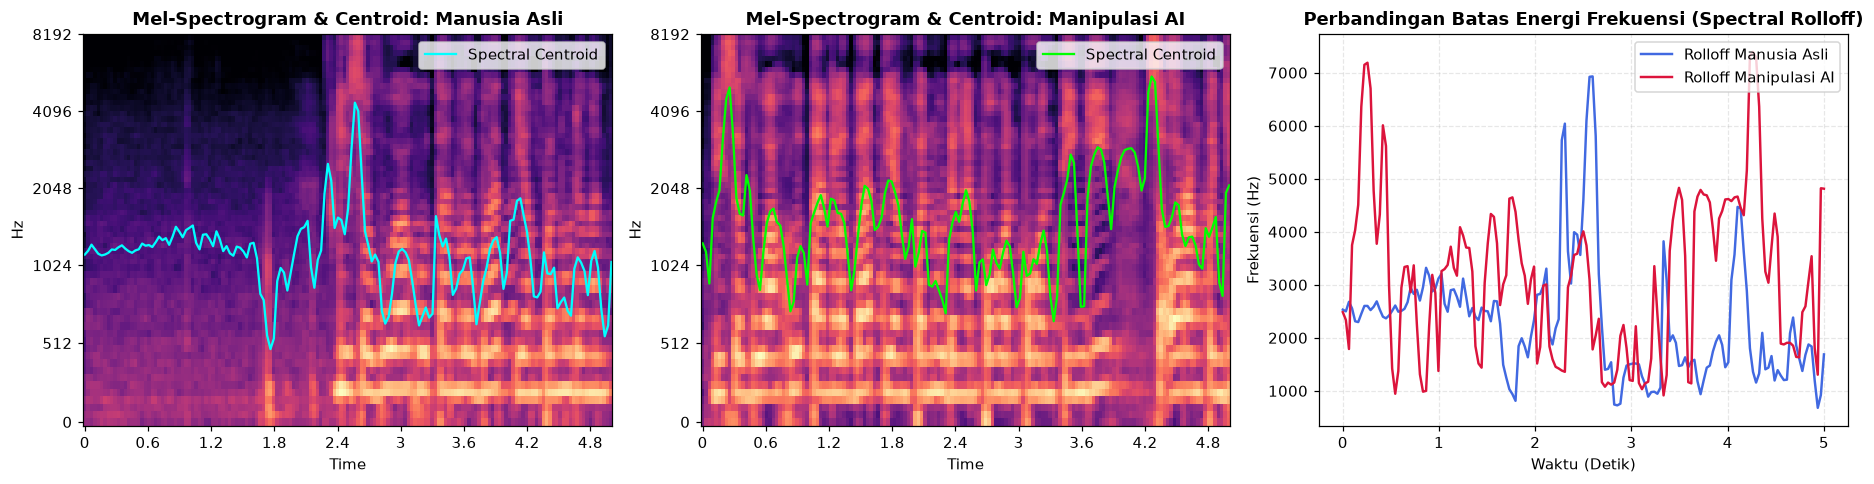

In [17]:
S_asli = np.abs(librosa.stft(y_asli_5s))
S_ai   = np.abs(librosa.stft(y_ai_5s))

cent_asli = librosa.feature.spectral_centroid(S=S_asli, sr=sr)[0]
cent_ai   = librosa.feature.spectral_centroid(S=S_ai, sr=sr)[0]
roll_asli = librosa.feature.spectral_rolloff(S=S_asli, sr=sr)[0]
roll_ai   = librosa.feature.spectral_rolloff(S=S_ai, sr=sr)[0]
bw_asli   = librosa.feature.spectral_bandwidth(S=S_asli, sr=sr)[0]
bw_ai     = librosa.feature.spectral_bandwidth(S=S_ai, sr=sr)[0]

df_eda_spec = pd.DataFrame({
    'Metrik Spektral Frekuensi (0-5 Detik)': ['Spectral Centroid Mean (Hz)', 'Spectral Bandwidth Mean (Hz)', 'Spectral Rolloff Mean (Hz)', 'Spectral Flatness Mean', 'Spectral Contrast Mean (dB)'],
    'Sampel Manusia Asli (audio_001)': [round(float(np.mean(cent_asli)), 2), round(float(np.mean(bw_asli)), 2), round(float(np.mean(roll_asli)), 2), round(float(np.mean(librosa.feature.spectral_flatness(S=S_asli))), 5), round(float(np.mean(librosa.feature.spectral_contrast(S=S_asli, sr=sr))), 2)],
    'Sampel Manipulasi AI (audio_001)': [round(float(np.mean(cent_ai)), 2), round(float(np.mean(bw_ai)), 2), round(float(np.mean(roll_ai)), 2), round(float(np.mean(librosa.feature.spectral_flatness(S=S_ai))), 5), round(float(np.mean(librosa.feature.spectral_contrast(S=S_ai, sr=sr))), 2)]
})
print('Perbandingan Statistik Fitur Spektral Frekuensi (Potongan 0-5 Detik):')
display(df_eda_spec)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Plot 1: Mel-Spectrogram Manusia Asli + Kurva Spectral Centroid
S_mel_asli = librosa.power_to_db(librosa.feature.melspectrogram(y=y_asli_5s, sr=sr, n_mels=64), ref=np.max)
librosa.display.specshow(S_mel_asli, sr=sr, x_axis='time', y_axis='mel', ax=axes[0], cmap='magma')
axes[0].plot(waktu_frame, cent_asli, color='cyan', linewidth=1.5, label='Spectral Centroid')
axes[0].set_title('Mel-Spectrogram & Centroid: Manusia Asli', fontweight='bold')
axes[0].legend(loc='upper right')

# Plot 2: Mel-Spectrogram Manipulasi AI + Kurva Spectral Centroid
S_mel_ai = librosa.power_to_db(librosa.feature.melspectrogram(y=y_ai_5s, sr=sr, n_mels=64), ref=np.max)
librosa.display.specshow(S_mel_ai, sr=sr, x_axis='time', y_axis='mel', ax=axes[1], cmap='magma')
axes[1].plot(waktu_frame, cent_ai, color='lime', linewidth=1.5, label='Spectral Centroid')
axes[1].set_title('Mel-Spectrogram & Centroid: Manipulasi AI', fontweight='bold')
axes[1].legend(loc='upper right')

# Plot 3: Perbandingan Kurva Spectral Rolloff
axes[2].plot(waktu_frame, roll_asli, color='royalblue', linewidth=1.6, label='Rolloff Manusia Asli')
axes[2].plot(waktu_frame, roll_ai, color='crimson', linewidth=1.6, label='Rolloff Manipulasi AI')
axes[2].set_title('Perbandingan Batas Energi Frekuensi (Spectral Rolloff)', fontweight='bold')
axes[2].set_xlabel('Waktu (Detik)')
axes[2].set_ylabel('Frekuensi (Hz)')
axes[2].legend(loc='upper right')
axes[2].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

---
## 2.4 Eksplorasi Frekuensi Dasar Pita Suara (*Pitch $F_0$*) & Saluran Vokal (*MFCC 1–13*)
Dua karakteristik biometrik terpenting yang membedakan manusia biologis dan mesin *vocoder* AI adalah:
1. **Frekuensi Dasar Pita Suara (*Fundamental Frequency / Pitch $F_0$ & Jitter*):**
   - Pita suara manusia merupakan jaringan otot biologis yang selalu memiliki getaran mikro alami (*micro-tremor / jitter*) dan variasi intonasi (`f0_std`).
   - Sebaliknya, model *Text-to-Speech* / *AI Voice* sering menghasilkan transisi *pitch* yang terlalu mulus atau memiliki pola patahan yang tidak alami.
2. ***Mel-Frequency Cepstral Coefficients* (`MFCC 1` s/d `MFCC 13`) & `Delta MFCC`:**
   - **MFCC** merepresentasikan bentuk fisik rongga saluran vokal manusia (tenggorokan, rongga mulut, lidah, dan rongga hidung).
   - Koefisien bawah (`MFCC 1–4`) menangkap selubung energi umum vokal, sedangkan koefisien menengah-atas (`MFCC 5–13`, terutama **`mfcc_8`**, **`mfcc_11`**, dan **`mfcc_7`**) menangkap detail mikro harmonik dan tekstur resonansi yang **paling sulit ditiru oleh neural vocoder AI**.

PERBANDINGAN PITCH (F0) & MFCC (5 DETIK PERTAMA audio_001.wav)
Manusia Asli  -> F0 Mean: 172.23 Hz | F0 Std: 75.90 Hz | MFCC-8 Mean: -5.48 | MFCC-11 Mean: -1.09
Manipulasi AI -> F0 Mean: 229.30 Hz | F0 Std: 37.21 Hz | MFCC-8 Mean: -10.37 | MFCC-11 Mean: -2.75


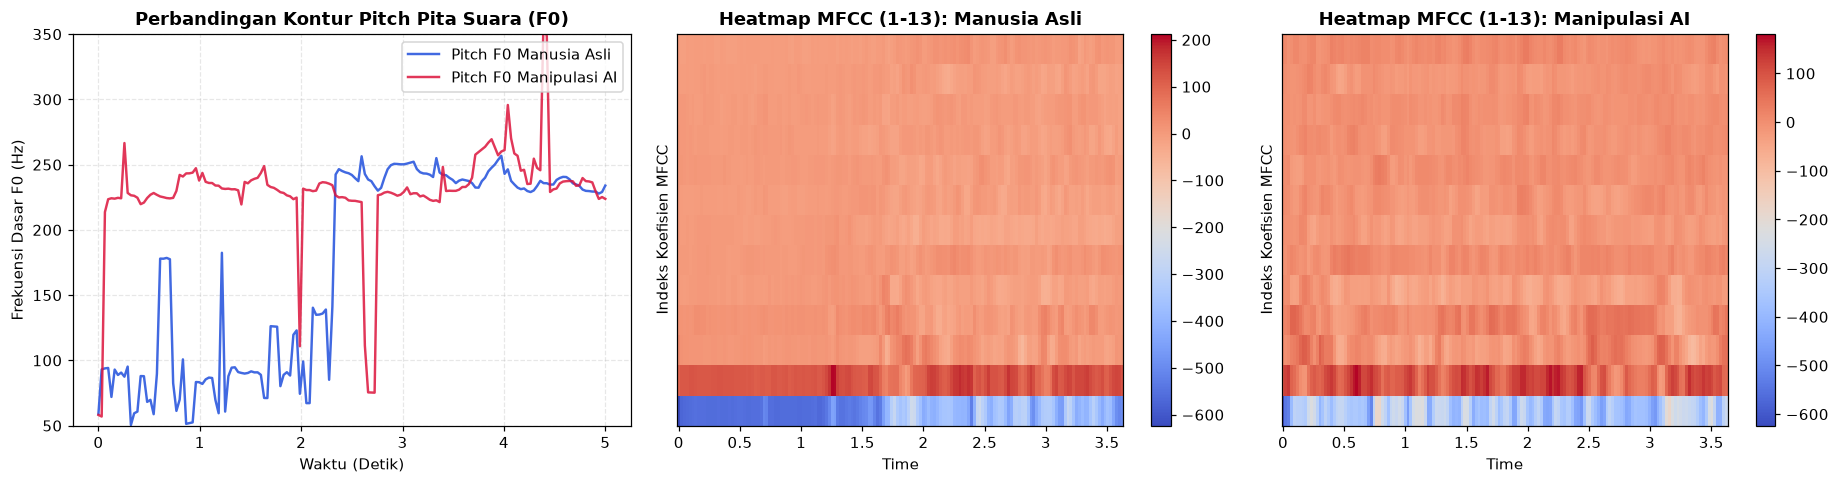

In [18]:
f0_asli_5s = librosa.yin(y_asli_5s, fmin=50, fmax=400, sr=sr)
f0_ai_5s   = librosa.yin(y_ai_5s, fmin=50, fmax=400, sr=sr)

mel_asli = librosa.feature.melspectrogram(S=S_asli**2, sr=sr)
mel_ai   = librosa.feature.melspectrogram(S=S_ai**2, sr=sr)
mfcc_asli = librosa.feature.mfcc(S=librosa.power_to_db(mel_asli), sr=sr, n_mfcc=13)
mfcc_ai   = librosa.feature.mfcc(S=librosa.power_to_db(mel_ai), sr=sr, n_mfcc=13)

print('==============================================================')
print('PERBANDINGAN PITCH (F0) & MFCC (5 DETIK PERTAMA audio_001.wav)')
print('==============================================================')
print(f'Manusia Asli  -> F0 Mean: {np.mean(f0_asli_5s):.2f} Hz | F0 Std: {np.std(f0_asli_5s):.2f} Hz | MFCC-8 Mean: {np.mean(mfcc_asli[7]):.2f} | MFCC-11 Mean: {np.mean(mfcc_asli[10]):.2f}')
print(f'Manipulasi AI -> F0 Mean: {np.mean(f0_ai_5s):.2f} Hz | F0 Std: {np.std(f0_ai_5s):.2f} Hz | MFCC-8 Mean: {np.mean(mfcc_ai[7]):.2f} | MFCC-11 Mean: {np.mean(mfcc_ai[10]):.2f}')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Plot 1: Kontur Pitch F0 Manusia Asli vs Manipulasi AI
t_f0 = np.linspace(0, 5, len(f0_asli_5s))
axes[0].plot(t_f0, f0_asli_5s, color='royalblue', linewidth=1.6, label='Pitch F0 Manusia Asli')
axes[0].plot(t_f0, f0_ai_5s, color='crimson', linewidth=1.6, alpha=0.85, label='Pitch F0 Manipulasi AI')
axes[0].set_title('Perbandingan Kontur Pitch Pita Suara (F0)', fontweight='bold')
axes[0].set_xlabel('Waktu (Detik)')
axes[0].set_ylabel('Frekuensi Dasar F0 (Hz)')
axes[0].set_ylim(50, 350)
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.3)

# Plot 2: Heatmap MFCC 1-13 Manusia Asli
img1 = librosa.display.specshow(mfcc_asli, x_axis='time', ax=axes[1], cmap='coolwarm')
axes[1].set_title('Heatmap MFCC (1-13): Manusia Asli', fontweight='bold')
axes[1].set_ylabel('Indeks Koefisien MFCC')
fig.colorbar(img1, ax=axes[1])

# Plot 3: Heatmap MFCC 1-13 Manipulasi AI
img2 = librosa.display.specshow(mfcc_ai, x_axis='time', ax=axes[2], cmap='coolwarm')
axes[2].set_title('Heatmap MFCC (1-13): Manipulasi AI', fontweight='bold')
axes[2].set_ylabel('Indeks Koefisien MFCC')
fig.colorbar(img2, ax=axes[2])

plt.tight_layout()
plt.show()

---
# Tahap 3: *Data Preparation* (Segmentasi, Ekstraksi 48 Fitur, Analisis Pengaruh Fitur, & Seleksi Fitur)

Tahap ketiga **CRISP-DM** merupakan tahap paling krusial yang menentukan kualitas model. Agar sistematis dan transparan, tahap ini dibagi menjadi **7 sub-tahap terpisah**:
1. **3.1 Strategi Segmentasi Audio (30 Detik $\rightarrow$ 6 Segmen @ 5 Detik)**
2. **3.2 Penjelasan Lengkap 48 Fitur yang Diekstrak & Pembuatan `fitur_audio_5s.csv`**
3. **3.3 Pembersihan Data (*Data Cleaning*) & Deteksi *Outlier* (Metode IQR)**
4. **3.4 Analisis Pengaruh Seluruh 48 Fitur (Peringkat Korelasi & *Feature Importance*)**
5. **3.5 Visualisasi Distribusi Fitur Paling Berpengaruh & Matriks Korelasi**
6. **3.6 Seleksi Fitur (*Feature Selection*): Menentukan Fitur Apa Saja yang Digunakan & Alasannya**
7. **3.7 Pembagian Data (*Group Train-Test Split*) & Normalisasi (`StandardScaler`)**

---
## 3.1 Strategi Segmentasi Audio (30 Detik $\rightarrow$ 6 Segmen @ 5 Detik)
Mengapa setiap file rekaman berdurasi **30 detik** kita potong menjadi **6 segmen berdurasi 5 detik**?
- Jika fitur diekstrak langsung dari rata-rata 30 detik penuh, fluktuasi lokal artefak AI menjadi terlalu teredam (*over-smoothed*) dan jumlah data hanya 200 baris.
- Sebaliknya, potongan **5 detik** (`80.000` titik sampel pada `16.000 Hz`) merupakan durasi ideal yang cukup panjang untuk memuat satu kalimat utuh beserta jeda napas dan intonasi, sekaligus melipatgandakan ukuran dataset menjadi **1.200 baris segmen** (`600 asli_human` vs `600 ai_manipulasi`).

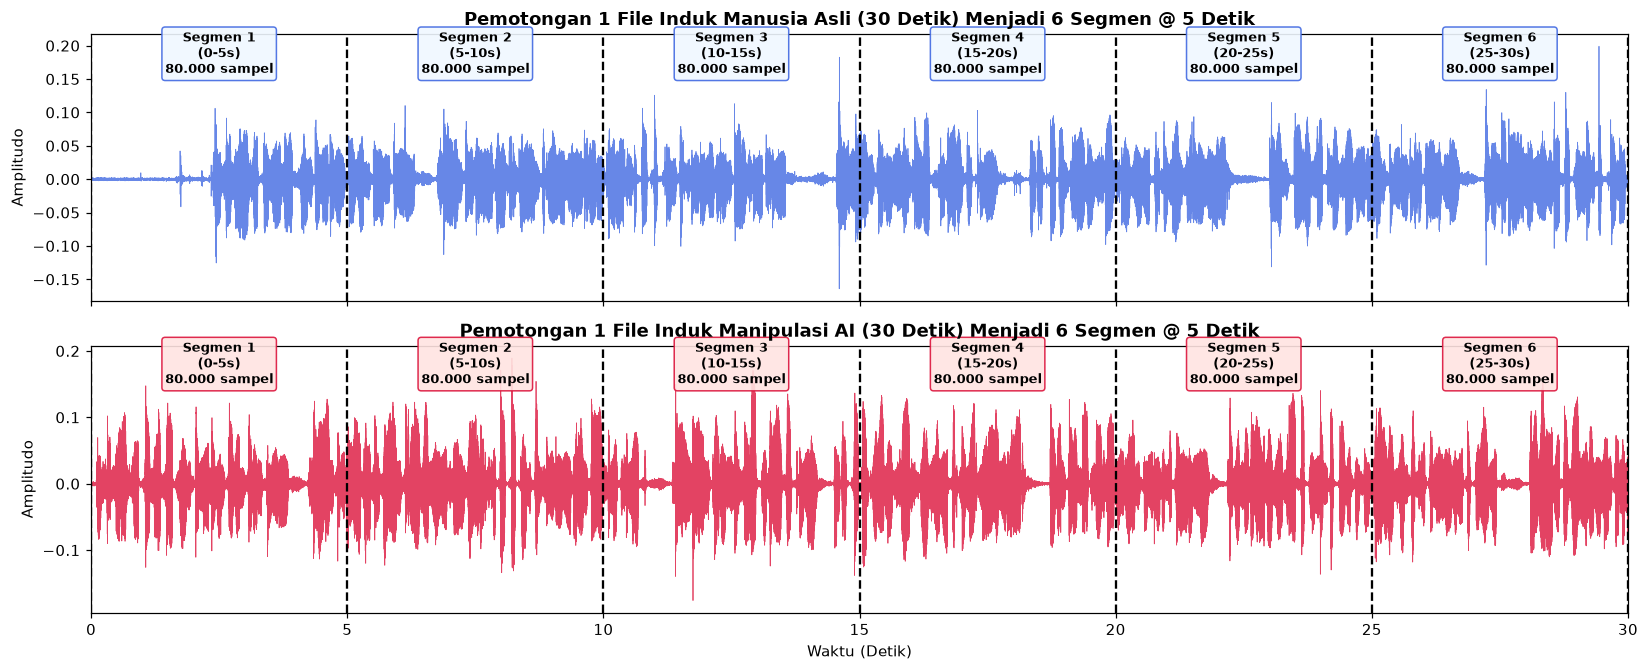

In [19]:
waktu_30s = np.linspace(0, 30, len(y_asli))

fig, axes = plt.subplots(2, 1, figsize=(15, 6.2), sharex=True)

# Plot 1: Pemotongan 6 Segmen pada Sampel Manusia Asli
axes[0].plot(waktu_30s, y_asli, color='royalblue', alpha=0.8, linewidth=0.5)
for batas in range(0, 35, 5):
    axes[0].axvline(batas, color='black', linestyle='--', linewidth=1.5)
    if batas < 30:
        axes[0].text(batas + 2.5, max(y_asli)*0.80, f'Segmen {batas//5 + 1}\n({batas}-{batas+5}s)\n80.000 sampel',
                     ha='center', fontsize=8.5, fontweight='bold',
                     bbox=dict(boxstyle='round,pad=0.25', facecolor='aliceblue', edgecolor='royalblue', alpha=0.9))
axes[0].set_title('Pemotongan 1 File Induk Manusia Asli (30 Detik) Menjadi 6 Segmen @ 5 Detik', fontweight='bold')
axes[0].set_ylabel('Amplitudo')
axes[0].set_xlim(0, 30)

# Plot 2: Pemotongan 6 Segmen pada Sampel Manipulasi AI
axes[1].plot(waktu_30s, y_ai, color='crimson', alpha=0.8, linewidth=0.5)
for batas in range(0, 35, 5):
    axes[1].axvline(batas, color='black', linestyle='--', linewidth=1.5)
    if batas < 30:
        axes[1].text(batas + 2.5, max(y_ai)*0.80, f'Segmen {batas//5 + 1}\n({batas}-{batas+5}s)\n80.000 sampel',
                     ha='center', fontsize=8.5, fontweight='bold',
                     bbox=dict(boxstyle='round,pad=0.25', facecolor='mistyrose', edgecolor='crimson', alpha=0.9))
axes[1].set_title('Pemotongan 1 File Induk Manipulasi AI (30 Detik) Menjadi 6 Segmen @ 5 Detik', fontweight='bold')
axes[1].set_xlabel('Waktu (Detik)')
axes[1].set_ylabel('Amplitudo')
axes[1].set_xlim(0, 30)

plt.tight_layout()
plt.show()

---
## 3.2 Kamus Lengkap 48 Fitur Audio yang Diekstrak (`fitur_audio_5s.csv`)
Untuk setiap segmen berdurasi **5 detik**, kita mengekstrak total **48 fitur numerik** menggunakan `librosa` dan `scipy.stats` yang terbagi ke dalam **4 Kelompok Karakteristik Akustik**:

| No | Kelompok Fitur | Nama Fitur dalam Tabel CSV | Jumlah | Penjelasan Fisik & Kegunaan dalam Deteksi Suara AI |
| :-: | :--- | :--- | :-: | :--- |
| **1** | **Domain Waktu (*Time-Domain*)** | `rms_mean`, `rms_std`, `zcr_mean`, `zcr_std`, `silence_ratio`, `skewness`, `kurtosis` | **7 Fitur** | Mengukur energi rata-rata & variasi keras-lembut suara (`rms`), kekasaran/desis konsonan (`zcr`), proporsi jeda napas (`silence_ratio`), serta ketidaksimetrisan bentuk gelombang (`skewness` & `kurtosis`). |
| **2** | **Domain Frekuensi (*Spectral*)** | `centroid_mean`, `centroid_std`, `bandwidth_mean`, `bandwidth_std`, `rolloff_mean`, `rolloff_std`, `flatness_mean`, `flatness_std`, `contrast_mean`, `contrast_std` | **10 Fitur** | Mengukur titik pusat kecerahan frekuensi (`centroid`), lebar pita frekuensi (`bandwidth`), batas 85% energi frekuensi (`rolloff`), tingkat kemiripan dengan *noise* sintetis (`flatness`), dan kontras puncak-lembah harmonik (`contrast`). |
| **3** | **Frekuensi Dasar Pita Suara (*Pitch $F_0$*)** | `f0_mean`, `f0_std`, `f0_jitter` | **3 Fitur** | Mengukur tinggi nada rata-rata pita suara (`f0_mean`), variasi intonasi bicara (`f0_std`), dan getaran mikro alami antar-frame pita suara (`f0_jitter`). |
| **4** | **Saluran Vokal (*Cepstral / MFCC*)** | `mfcc_1_mean` .. `mfcc_13_mean` (13), `mfcc_1_std` .. `mfcc_13_std` (13), `delta_mfcc_mean`, `delta_mfcc_std` (2) | **28 Fitur** | Memodelkan bentuk rongga saluran suara manusia (*vocal tract*) serta kecepatan perubahan artikulasi (`delta_mfcc`). Koefisien menengah-tinggi (`mfcc_4` s/d `mfcc_13`) sangat sensitif menangkap jejak *neural vocoder* AI. |
| | **TOTAL FITUR DIEKSTRAK** | **Seluruh kandidat fitur awal** | **48 Fitur** | Ditambah 6 kolom identitas (`id_sampel`, `file_induk`, `segmen_ke`, `durasi_detik`, `kelas`, `label`) = **54 kolom**. |

TABEL FITUR SEGMEN 5 DETIK (fitur_audio_5s.csv)
Ukuran Tabel     : 1200 baris segmen x 54 kolom
Total Fitur Audio: 48 fitur numerik


,id_sampel,file_induk,segmen_ke,durasi_detik,kelas,label,rms_mean,rms_std,zcr_mean,zcr_std,...,mfcc_9_mean,mfcc_9_std,mfcc_10_mean,mfcc_10_std,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std
0,asli_human_audio_001_seg1,audio_001.wav,1,5,asli_human,0,0.013955,0.012787,0.067019,0.042272,...,-0.673903,9.523523,-2.999087,8.972865,-1.086063,6.968936,-4.989025,8.967397,1.587183,9.068581
1,asli_human_audio_001_seg2,audio_001.wav,2,5,asli_human,0,0.021849,0.006960,0.093535,0.107938,...,-4.000465,10.961783,-3.102987,9.536517,-2.772823,8.574529,-3.708979,8.855739,2.496301,8.634275
2,asli_human_audio_001_seg3,audio_001.wav,3,5,asli_human,0,0.017732,0.009815,0.134305,0.126548,...,-1.969587,9.549408,-0.898694,8.958740,-4.506124,7.656307,-0.791555,8.556320,0.033050,8.762108
3,asli_human_audio_001_seg4,audio_001.wav,4,5,asli_human,0,0.019516,0.008672,0.098779,0.072077,...,1.371567,9.173651,-4.212220,10.140523,-6.682798,8.555773,-3.988583,7.342093,0.475900,8.598063
4,asli_human_audio_001_seg5,audio_001.wav,5,5,asli_human,0,0.019679,0.009535,0.109033,0.113210,...,3.210985,9.686152,-3.424584,8.098941,-6.605156,9.907909,-2.374298,7.601110,1.046081,7.166265
5,asli_human_audio_001_seg6,audio_001.wav,6,5,asli_human,0,0.021873,0.008271,0.071012,0.062909,...,-0.093234,10.036243,-8.571313,11.443818,-5.331596,8.774360,-1.971982,7.846374,1.602793,7.772292


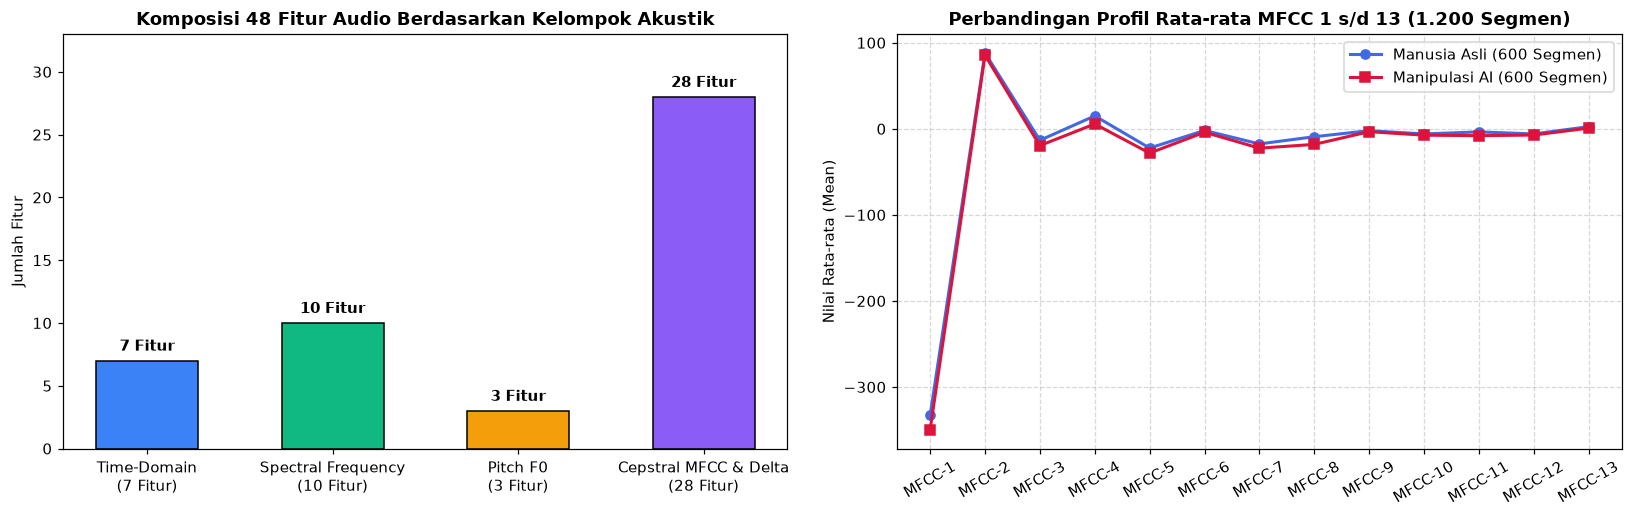

In [20]:
out_dir = '../../data/dataset_audio_kaggle'
csv_5s  = os.path.join(out_dir, 'fitur_audio_5s.csv')

def ekstrak_fitur_segmen(y_seg, sr, f0_seg):
    """Mengekstrak 48 fitur audio dari 1 segmen suara berdurasi 5 detik."""    # 1. Kelompok Time-Domain (7 fitur)
    rms = librosa.feature.rms(y=y_seg)[0]
    zcr = librosa.feature.zero_crossing_rate(y=y_seg)[0]
    silence_ratio = float(np.mean(rms < 0.01) * 100.0)
    skew_val = float(stats.skew(y_seg))
    kurt_val = float(stats.kurtosis(y_seg))

    # 2. Kelompok Frequency / Spectral (10 fitur)
    S = np.abs(librosa.stft(y_seg))
    centroid  = librosa.feature.spectral_centroid(S=S, sr=sr)[0]
    bandwidth = librosa.feature.spectral_bandwidth(S=S, sr=sr)[0]
    rolloff   = librosa.feature.spectral_rolloff(S=S, sr=sr)[0]
    flatness  = librosa.feature.spectral_flatness(S=S)[0]
    contrast  = librosa.feature.spectral_contrast(S=S, sr=sr)

    # 3. Kelompok Pitch / Fundamental Frequency F0 (3 fitur)
    voiced_mask = rms[:len(f0_seg)] > 0.01
    f0_voiced = f0_seg[voiced_mask] if np.any(voiced_mask) else f0_seg
    f0_mean   = float(np.mean(f0_voiced))
    f0_std    = float(np.std(f0_voiced))
    f0_jitter = float(np.mean(np.abs(np.diff(f0_voiced)))) if len(f0_voiced) > 1 else 0.0

    # 4. Kelompok Cepstral / MFCC 1-13 & Delta MFCC (28 fitur)
    mel_S = librosa.feature.melspectrogram(S=S**2, sr=sr)
    mfcc = librosa.feature.mfcc(S=librosa.power_to_db(mel_S), sr=sr, n_mfcc=13)
    delta_mfcc = librosa.feature.delta(mfcc)

    fitur = {
        'rms_mean': float(np.mean(rms)),
        'rms_std': float(np.std(rms)),
        'zcr_mean': float(np.mean(zcr)),
        'zcr_std': float(np.std(zcr)),
        'silence_ratio': silence_ratio,
        'skewness': skew_val,
        'kurtosis': kurt_val,
        'centroid_mean': float(np.mean(centroid)),
        'centroid_std': float(np.std(centroid)),
        'bandwidth_mean': float(np.mean(bandwidth)),
        'bandwidth_std': float(np.std(bandwidth)),
        'rolloff_mean': float(np.mean(rolloff)),
        'rolloff_std': float(np.std(rolloff)),
        'flatness_mean': float(np.mean(flatness)),
        'flatness_std': float(np.std(flatness)),
        'contrast_mean': float(np.mean(contrast)),
        'contrast_std': float(np.std(contrast)),
        'f0_mean': f0_mean,
        'f0_std': f0_std,
        'f0_jitter': f0_jitter,
        'delta_mfcc_mean': float(np.mean(delta_mfcc)),
        'delta_mfcc_std': float(np.std(delta_mfcc)),
    }
    for i in range(13):
        fitur[f'mfcc_{i+1}_mean'] = float(np.mean(mfcc[i]))
        fitur[f'mfcc_{i+1}_std']  = float(np.std(mfcc[i]))
    return fitur

def proses_satu_file_5s(args):
    nama_kelas, label_id, nama_file, full_path = args
    y_30s, sr = sf.read(full_path, dtype='float32')
    kode_file = nama_file.replace('.wav', '')
    f0_30s = librosa.yin(y_30s, fmin=50, fmax=400, sr=sr)
    total_f0 = len(f0_30s)
    rows_5s = []
    sampel_5s = 5 * sr
    for seg_idx in range(6):
        y_5s = y_30s[seg_idx * sampel_5s : (seg_idx + 1) * sampel_5s]
        f0_5s = f0_30s[int(seg_idx * total_f0 / 6) : int((seg_idx + 1) * total_f0 / 6)]
        meta_5s = {
            'id_sampel': f'{nama_kelas}_{kode_file}_seg{seg_idx+1}',
            'file_induk': nama_file,
            'segmen_ke': seg_idx + 1,
            'durasi_detik': 5,
            'kelas': nama_kelas,
            'label': label_id
        }
        meta_5s.update(ekstrak_fitur_segmen(y_5s, sr, f0_5s))
        rows_5s.append(meta_5s)
    return rows_5s

if not os.path.exists(csv_5s):
    daftar_tugas = []
    for nama_kelas, label_id in [('asli_human', 0), ('ai_manipulasi', 1)]:
        folder_path = os.path.join(base_dir, nama_kelas)
        for nama_file in sorted([f for f in os.listdir(folder_path) if f.endswith('.wav')]):
            daftar_tugas.append((nama_kelas, label_id, nama_file, os.path.join(folder_path, nama_file)))
    print(f'Mengekstrak 48 fitur pada segmen 5 detik untuk {len(daftar_tugas)} file induk...')
    all_5s = []
    with ThreadPoolExecutor(max_workers=8) as executor:
        for r5 in executor.map(proses_satu_file_5s, daftar_tugas):
            all_5s.extend(r5)
    df_5s = pd.DataFrame(all_5s)
    df_5s.to_csv(csv_5s, index=False)
else:
    df_5s = pd.read_csv(csv_5s)

kolom_meta  = [c for c in ['id_sampel', 'file_induk', 'blok_10s', 'segmen_5s', 'segmen_ke', 'durasi_detik', 'kelas', 'label'] if c in df_5s.columns]
kolom_fitur = [c for c in df_5s.columns if c not in kolom_meta]

print('==============================================================')
print('TABEL FITUR SEGMEN 5 DETIK (fitur_audio_5s.csv)')
print('==============================================================')
print(f'Ukuran Tabel     : {df_5s.shape[0]} baris segmen x {df_5s.shape[1]} kolom')
print(f'Total Fitur Audio: {len(kolom_fitur)} fitur numerik')
display(df_5s.head(6))

# Visualisasi Proporsi 4 Kelompok Fitur & Profil Rata-rata MFCC 1-13
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

kelompok_nama = ['Time-Domain\n(7 Fitur)', 'Spectral Frequency\n(10 Fitur)', 'Pitch F0\n(3 Fitur)', 'Cepstral MFCC & Delta\n(28 Fitur)']
kelompok_jml  = [7, 10, 3, 28]
warna_klp     = ['#3b82f6', '#10b981', '#f59e0b', '#8b5cf6']
bars = axes[0].bar(kelompok_nama, kelompok_jml, color=warna_klp, edgecolor='black', width=0.55)
axes[0].set_title('Komposisi 48 Fitur Audio Berdasarkan Kelompok Akustik', fontweight='bold')
axes[0].set_ylabel('Jumlah Fitur')
axes[0].set_ylim(0, 33)
for b in bars:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.8, f'{int(b.get_height())} Fitur', ha='center', fontweight='bold')

mfcc_cols = [f'mfcc_{i}_mean' for i in range(1, 14)]
mean_mfcc_asli = df_5s[df_5s['label']==0][mfcc_cols].mean().values
mean_mfcc_ai   = df_5s[df_5s['label']==1][mfcc_cols].mean().values
x_idx = np.arange(1, 14)
axes[1].plot(x_idx, mean_mfcc_asli, marker='o', linewidth=2, color='royalblue', label='Manusia Asli (600 Segmen)')
axes[1].plot(x_idx, mean_mfcc_ai, marker='s', linewidth=2, color='crimson', label='Manipulasi AI (600 Segmen)')
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels([f'MFCC-{i}' for i in x_idx], rotation=30)
axes[1].set_title('Perbandingan Profil Rata-rata MFCC 1 s/d 13 (1.200 Segmen)', fontweight='bold')
axes[1].set_ylabel('Nilai Rata-rata (Mean)')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 3.3 Pembersihan Data (*Data Cleaning*) & Deteksi *Outlier* (Metode IQR)
Sebelum menganalisis pengaruh fitur, kita melakukan pemeriksaan kualitas tabel `fitur_audio_5s.csv`:
1. **Pengecekan *Missing Value* (`NaN` / `Null`):** Memastikan tidak ada fitur yang gagal dihitung pada seluruh 1.200 segmen.
2. **Pengecekan Duplikasi Data:** Memastikan tidak ada segmen identik yang tercatat ganda.
3. **Deteksi *Outlier* dengan *Interquartile Range* (IQR):**
   - Suatu nilai fitur dikategorikan sebagai *outlier* jika berada di bawah $Q_1 - 1,5 \times \text{IQR}$ atau di atas $Q_3 + 1,5 \times \text{IQR}$.
   - Pada sinyal suara, *outlier* ringan (< 3%) merupakan hal wajar yang mencerminkan penekanan kata atau desis napas sesaat, sehingga tidak boleh dihapus sembarangan melainkan distandarisasi dengan `StandardScaler`.

RINGKASAN DATA CLEANING & DETEKSI OUTLIER (1.200 SEGMEN)
Jumlah Missing Value (NaN)     : 0
Jumlah Baris Duplikat          : 0
Rata-rata Outlier per Fitur    : 11.8 segmen (0.99% dari 1.200 segmen)

10 Fitur dengan Jumlah Outlier Tertinggi (Metode 1.5 x IQR):


,Nama Fitur,Jumlah Outlier (Segmen),Persentase Outlier (%)
0,mfcc_1_std,43,3.58
1,kurtosis,42,3.50
2,silence_ratio,41,3.42
3,rms_std,31,2.58
4,f0_jitter,23,1.92
5,flatness_std,21,1.75
6,contrast_mean,21,1.75
7,mfcc_5_mean,19,1.58
8,mfcc_9_mean,18,1.50
9,delta_mfcc_std,17,1.42


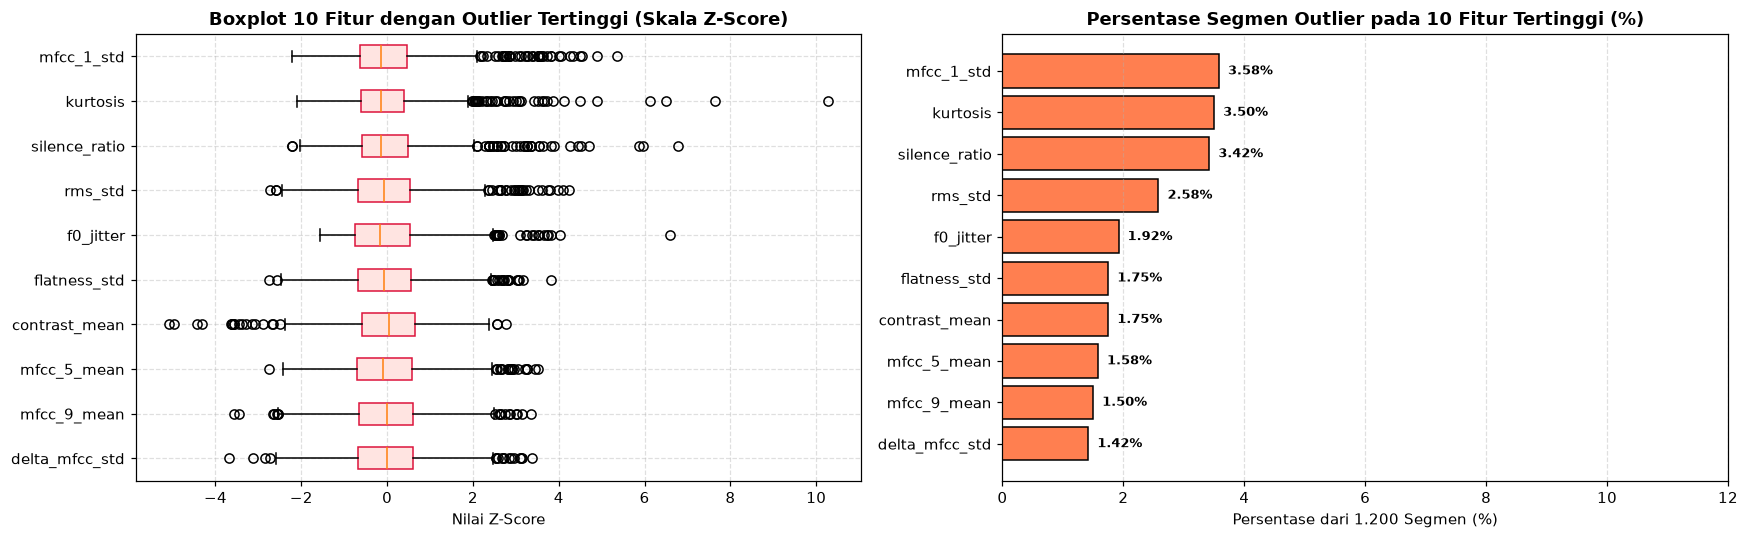

In [26]:
jml_nan = int(df_5s[kolom_fitur].isna().sum().sum())
jml_dup = int(df_5s.duplicated(subset=kolom_fitur).sum())

Q1 = df_5s[kolom_fitur].quantile(0.25)
Q3 = df_5s[kolom_fitur].quantile(0.75)
IQR = Q3 - Q1
outlier_counts = ((df_5s[kolom_fitur] < (Q1 - 1.5 * IQR)) | (df_5s[kolom_fitur] > (Q3 + 1.5 * IQR))).sum()
outlier_pct = (outlier_counts / len(df_5s)) * 100

print('==============================================================')
print('RINGKASAN DATA CLEANING & DETEKSI OUTLIER (1.200 SEGMEN)')
print('==============================================================')
print(f'Jumlah Missing Value (NaN)     : {jml_nan}')
print(f'Jumlah Baris Duplikat          : {jml_dup}')
print(f'Rata-rata Outlier per Fitur    : {outlier_counts.mean():.1f} segmen ({outlier_pct.mean():.2f}% dari 1.200 segmen)')

df_outlier_top10 = pd.DataFrame({
    'Nama Fitur': outlier_counts.sort_values(ascending=False).head(10).index,
    'Jumlah Outlier (Segmen)': outlier_counts.sort_values(ascending=False).head(10).values,
    'Persentase Outlier (%)': outlier_pct.sort_values(ascending=False).head(10).values.round(2)
})
print('\n10 Fitur dengan Jumlah Outlier Tertinggi (Metode 1.5 x IQR):')
display(df_outlier_top10)

# Visualisasi Boxplot (Z-Score) untuk Memeriksa Sebaran & Outlier
scaler_temp = StandardScaler()
X_all_z = pd.DataFrame(scaler_temp.fit_transform(df_5s[kolom_fitur]), columns=kolom_fitur)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Boxplot 10 Fitur dengan Outlier Tertinggi
top_out_cols = list(df_outlier_top10['Nama Fitur'])[::-1]
axes[0].boxplot(X_all_z[top_out_cols].values, tick_labels=top_out_cols, vert=False, patch_artist=True, boxprops=dict(facecolor='mistyrose', edgecolor='crimson'))
axes[0].set_title('Boxplot 10 Fitur dengan Outlier Tertinggi (Skala Z-Score)', fontweight='bold')
axes[0].set_xlabel('Nilai Z-Score')
axes[0].grid(True, linestyle='--', alpha=0.4)

# Plot 2: Persentase Outlier pada 10 Fitur Tersebut
bars = axes[1].barh(top_out_cols, df_outlier_top10['Persentase Outlier (%)'].values[::-1], color='coral', edgecolor='black')
axes[1].set_title('Persentase Segmen Outlier pada 10 Fitur Tertinggi (%)', fontweight='bold')
axes[1].set_xlabel('Persentase dari 1.200 Segmen (%)')
axes[1].set_xlim(0, 12)
for b in bars:
    axes[1].text(b.get_width() + 0.15, b.get_y() + b.get_height()/2, f'{b.get_width():.2f}%', va='center', fontweight='bold', fontsize=8.5)
axes[1].grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

---
## 3.4 Analisis Pengaruh Seluruh 48 Fitur: Fitur Apa Saja yang Paling Berpengaruh dan Kenapa?
Untuk menjawab pertanyaan **"Dari total 48 fitur yang diekstrak, fitur apa saja yang paling berpengaruh dalam membedakan suara manusia asli vs AI?"**, kita mengukur kekuatan setiap fitur menggunakan **2 metode objektif sekaligus**:
1. **Koefisien Korelasi Pearson Absolut ($|r|$) terhadap `label` (`0` vs `1`):** Mengukur kekuatan hubungan linier langsung antara nilai sebuah fitur dengan status keaslian suara.
2. **Bobot Kepentingan Pohon Keputusan (*Random Forest Gini Importance*):** Mengukur seberapa besar kontribusi sebuah fitur dalam menurunkan tingkat kesalahan (*impurity*) saat memisahkan kelas Manusia Asli dan AI.

### Mengapa Fitur-Fitur Tertentu Sangat Berpengaruh?
- **Dominasi Kelompok `MFCC` (`mfcc_8_mean`, `mfcc_11_mean`, `mfcc_7_mean`, `mfcc_8_std`, `mfcc_4_mean`, `mfcc_5_mean`, `mfcc_6_std`):**
  Koefisien MFCC orde menengah-tinggi merepresentasikan **detail resonansi mikro saluran vokal** (getaran dinding tenggorokan dan artikulasi bibir/lidah). Mesin *Text-to-Speech* / *AI Vocoder* mampu meniru frekuensi dasar (`f0_mean` atau `mfcc_1`), namun mengalami kesulitan meniru variasi mikro resonansi pada pita MFCC ke-4 hingga ke-11, sehingga nilai rata-rata dan standar deviasinya berbeda sangat tajam antara Manusia Asli dan AI.
- **Pengaruh Bentuk Gelombang (`skewness` & `kurtosis`):**
  Suara manusia asli memiliki ketidaksimetrisan tekanan udara (`skewness = -0.1526`) saat udara keluar dari paru-paru melewati pita suara, sedangkan gelombang sintetis AI cenderung simetris (`skewness = +0.0358`).

TABEL PERINGKAT 20 FITUR PALING BERPENGARUH (DARI TOTAL 48 FITUR)


,Nama Fitur,Kelompok Fitur,RF Importance (%),Korelasi |r|,Mean Manusia Asli (0),Mean Manipulasi AI (1)
Peringkat,,,,,,
1,mfcc_8_mean,4. Cepstral (MFCC),16.707,0.7513,-9.1623,-18.0866
2,mfcc_11_mean,4. Cepstral (MFCC),11.790,0.6810,-3.5710,-7.9541
3,mfcc_7_mean,4. Cepstral (MFCC),9.567,0.6334,-17.5586,-22.4891
4,mfcc_8_std,4. Cepstral (MFCC),9.008,0.6239,12.4351,14.3842
5,mfcc_4_mean,4. Cepstral (MFCC),5.326,0.5557,15.0244,5.6243
6,mfcc_5_mean,4. Cepstral (MFCC),5.150,0.5015,-22.3599,-28.2337
7,mfcc_6_std,4. Cepstral (MFCC),4.941,0.5337,13.9619,15.8537
8,skewness,1. Time-Domain,4.373,0.5091,-0.1526,0.0358
9,mfcc_4_std,4. Cepstral (MFCC),3.739,0.5282,25.1113,28.6975



10 FITUR DENGAN PENGARUH PALING RENDAH (URUTAN 39 s/d 48)


,Nama Fitur,Kelompok Fitur,RF Importance (%),Korelasi |r|,Mean Manusia Asli (0),Mean Manipulasi AI (1)
Peringkat,,,,,,
39,centroid_mean,2. Spectral Frequency,0.305,0.0300,1712.6570,1722.9387
40,bandwidth_std,2. Spectral Frequency,0.302,0.0234,355.1172,357.2604
41,mfcc_12_std,4. Cepstral (MFCC),0.302,0.1305,9.3515,9.0207
42,rolloff_mean,2. Spectral Frequency,0.290,0.0668,3233.9797,3189.0490
43,zcr_mean,1. Time-Domain,0.282,0.1502,0.1110,0.1166
44,zcr_std,1. Time-Domain,0.270,0.0143,0.0861,0.0855
45,rolloff_std,2. Spectral Frequency,0.257,0.0124,1352.2939,1356.5646
46,centroid_std,2. Spectral Frequency,0.208,0.0146,767.3207,771.5353
47,silence_ratio,1. Time-Domain,0.205,0.0424,15.9490,15.3471


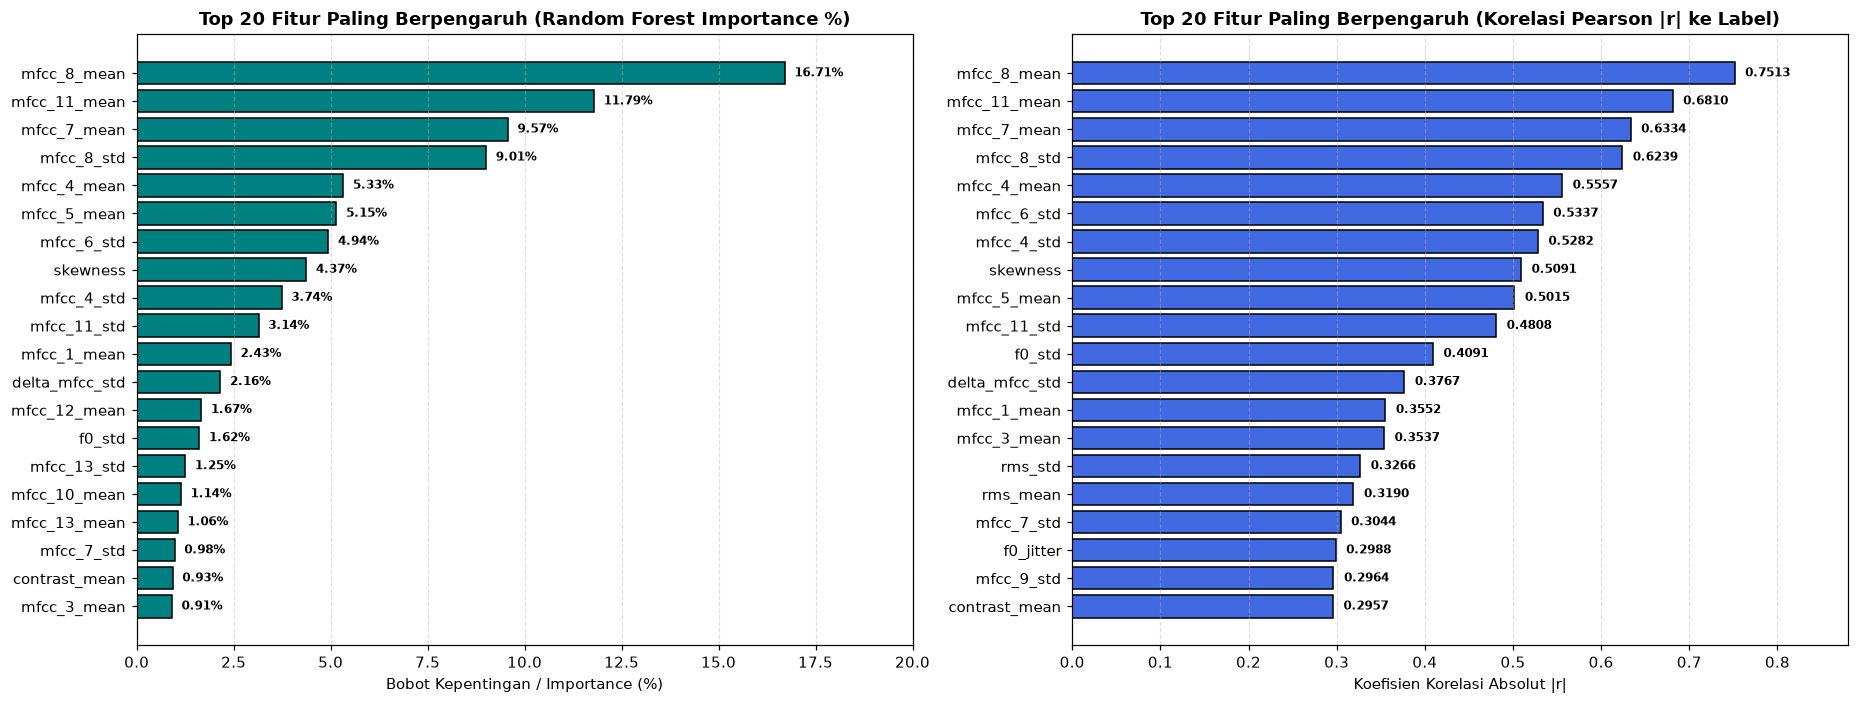

In [27]:
# Hitung Korelasi Pearson |r| dan Random Forest Importance untuk seluruh 48 fitur
daftar_file_unik = sorted(df_5s['file_induk'].unique())
train_files, test_files = train_test_split(daftar_file_unik, test_size=0.20, random_state=42)

df_train_raw = df_5s[df_5s['file_induk'].isin(train_files)].copy()
df_test_raw  = df_5s[df_5s['file_induk'].isin(test_files)].copy()

scaler_48 = StandardScaler()
X_tr_48 = scaler_48.fit_transform(df_train_raw[kolom_fitur].values)
y_tr_48 = df_train_raw['label'].values

rf_eval_48 = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_eval_48.fit(X_tr_48, y_tr_48)

korelasi_series = df_5s[kolom_fitur].apply(lambda x: x.corr(df_5s['label'])).abs()
importance_series = pd.Series(rf_eval_48.feature_importances_ * 100, index=kolom_fitur)

def kategori_kelompok(nama_f):
    if nama_f.startswith('mfcc') or nama_f.startswith('delta_mfcc'):
        return '4. Cepstral (MFCC)'
    elif nama_f.startswith('f0'):
        return '3. Pitch (F0)'
    elif nama_f in ['rms_mean', 'rms_std', 'zcr_mean', 'zcr_std', 'silence_ratio', 'skewness', 'kurtosis']:
        return '1. Time-Domain'
    else:
        return '2. Spectral Frequency'

df_peringkat_48 = pd.DataFrame({
    'Nama Fitur': kolom_fitur,
    'Kelompok Fitur': [kategori_kelompok(f) for f in kolom_fitur],
    'RF Importance (%)': [round(importance_series[f], 3) for f in kolom_fitur],
    'Korelasi |r|': [round(korelasi_series[f], 4) for f in kolom_fitur],
    'Mean Manusia Asli (0)': [round(df_5s[df_5s['label']==0][f].mean(), 4) for f in kolom_fitur],
    'Mean Manipulasi AI (1)': [round(df_5s[df_5s['label']==1][f].mean(), 4) for f in kolom_fitur]
}).sort_values(by='RF Importance (%)', ascending=False).reset_index(drop=True)
df_peringkat_48.index = df_peringkat_48.index + 1
df_peringkat_48.index.name = 'Peringkat'

print('==============================================================')
print('TABEL PERINGKAT 20 FITUR PALING BERPENGARUH (DARI TOTAL 48 FITUR)')
print('==============================================================')
display(df_peringkat_48.head(20))

print('\n==============================================================')
print('10 FITUR DENGAN PENGARUH PALING RENDAH (URUTAN 39 s/d 48)')
print('==============================================================')
display(df_peringkat_48.tail(10))

# Visualisasi Peringkat Pengaruh Fitur
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

# Plot 1: Top 20 Fitur berdasarkan Random Forest Importance (%)
top20_df = df_peringkat_48.head(20).iloc[::-1]
bars1 = axes[0].barh(top20_df['Nama Fitur'], top20_df['RF Importance (%)'], color='teal', edgecolor='black')
axes[0].set_title('Top 20 Fitur Paling Berpengaruh (Random Forest Importance %)', fontweight='bold')
axes[0].set_xlabel('Bobot Kepentingan / Importance (%)')
axes[0].set_xlim(0, 20)
for b in bars1:
    axes[0].text(b.get_width() + 0.25, b.get_y() + b.get_height()/2, f'{b.get_width():.2f}%', va='center', fontsize=8, fontweight='bold')
axes[0].grid(axis='x', linestyle='--', alpha=0.4)

# Plot 2: Top 20 Fitur berdasarkan Korelasi Absolut |r|
top20_kor = df_peringkat_48.sort_values(by='Korelasi |r|', ascending=False).head(20).iloc[::-1]
bars2 = axes[1].barh(top20_kor['Nama Fitur'], top20_kor['Korelasi |r|'], color='royalblue', edgecolor='black')
axes[1].set_title('Top 20 Fitur Paling Berpengaruh (Korelasi Pearson |r| ke Label)', fontweight='bold')
axes[1].set_xlabel('Koefisien Korelasi Absolut |r|')
axes[1].set_xlim(0, 0.88)
for b in bars2:
    axes[1].text(b.get_width() + 0.012, b.get_y() + b.get_height()/2, f'{b.get_width():.4f}', va='center', fontsize=8, fontweight='bold')
axes[1].grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

---
## 3.5 Visualisasi Distribusi 6 Fitur Paling Berpengaruh & Matriks Korelasi Antar-Fitur
Untuk membuktikan secara visual mengapa fitur-fitur teratas seperti **`mfcc_8_mean`**, **`mfcc_11_mean`**, **`mfcc_7_mean`**, **`mfcc_8_std`**, **`mfcc_4_mean`**, dan **`skewness`** mampu memisahkan suara Manusia Asli dan AI dengan sangat baik, mari kita tampilkan:
1. **Histogram Distribusi Kelas (`Asli Human` vs `AI Manipulasi`)** pada 6 fitur paling berpengaruh. Terlihat jelas bahwa kurva biru (Manusia Asli) dan kurva merah (Manipulasi AI) menempati rentang nilai yang terpisah jauh.
2. **Matriks Korelasi Antar-Fitur Terkuat (*Correlation Matrix Heatmap*)** untuk memeriksa apakah fitur-fitur unggulan tersebut saling independen atau redundan.

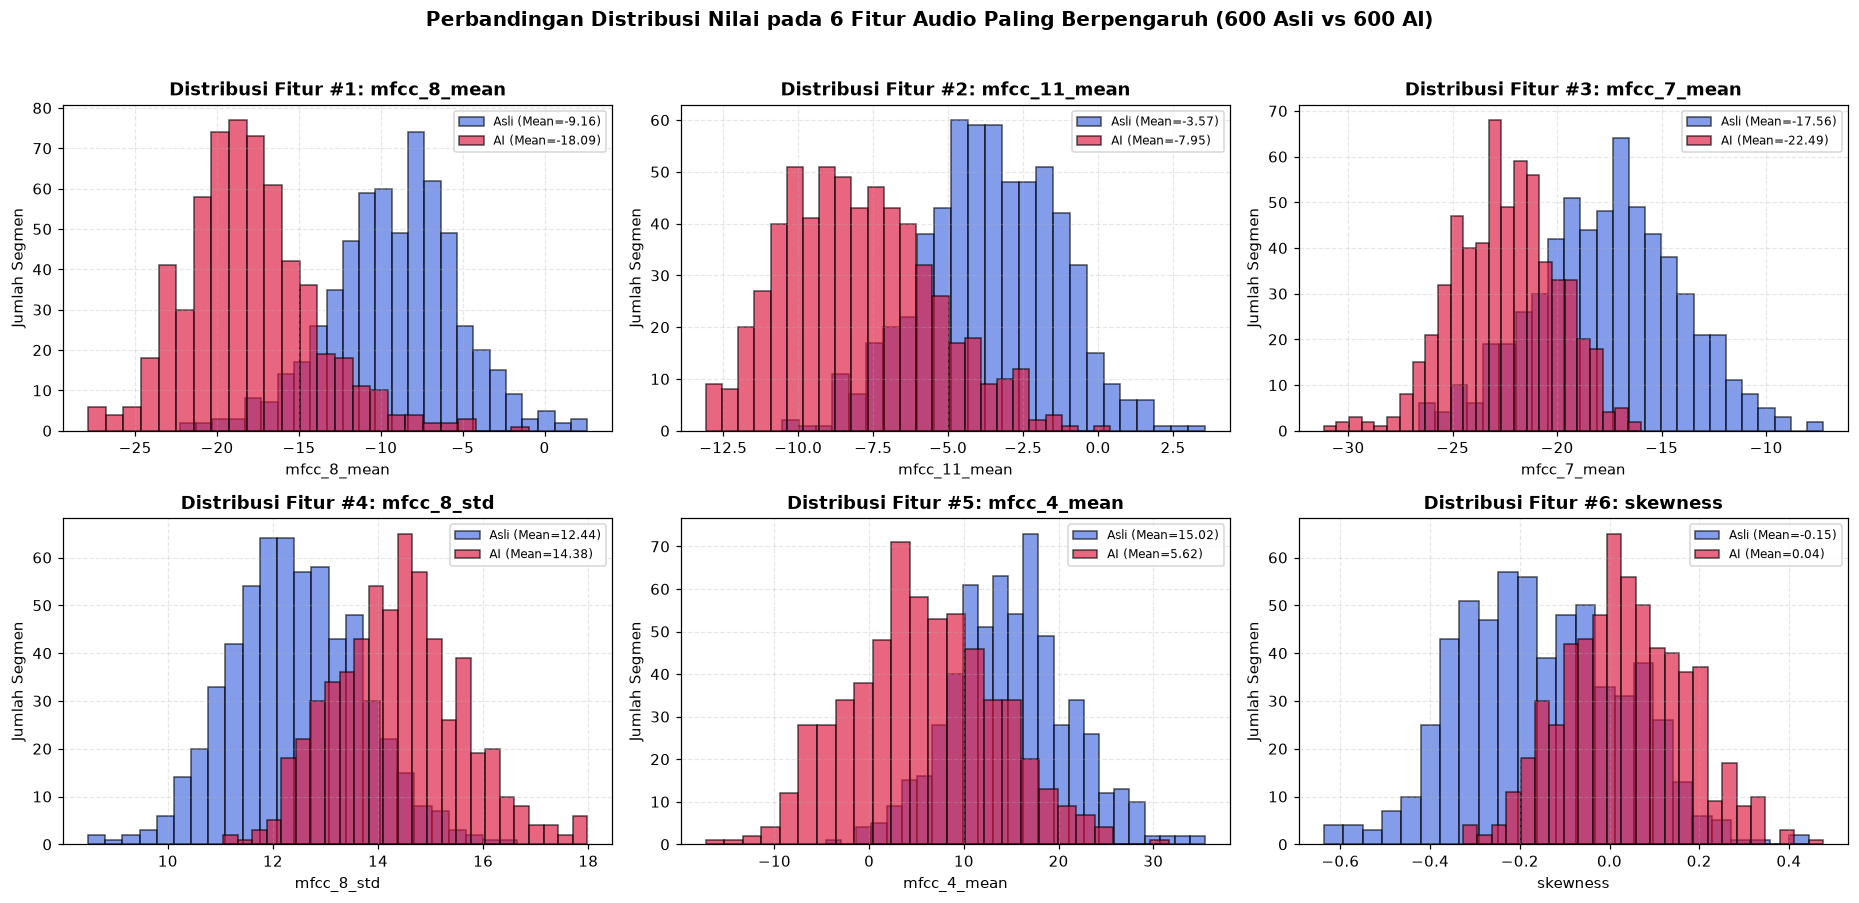

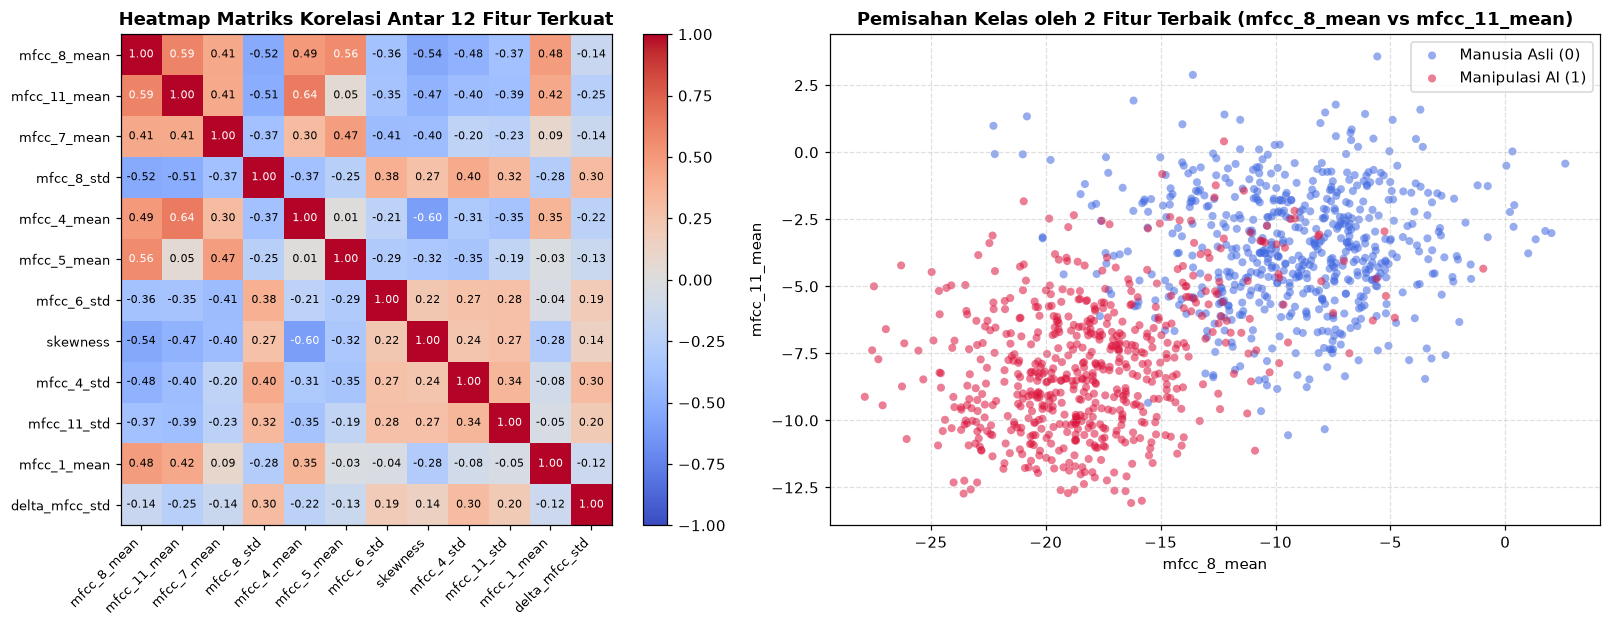

In [28]:
enam_fitur_utama = ['mfcc_8_mean', 'mfcc_11_mean', 'mfcc_7_mean', 'mfcc_8_std', 'mfcc_4_mean', 'skewness']

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
axes = axes.flatten()

for idx, nama_f in enumerate(enam_fitur_utama):
    val_asli = df_5s[df_5s['label']==0][nama_f]
    val_ai   = df_5s[df_5s['label']==1][nama_f]
    axes[idx].hist(val_asli, bins=25, alpha=0.65, color='royalblue', edgecolor='black', label=f'Asli (Mean={val_asli.mean():.2f})')
    axes[idx].hist(val_ai, bins=25, alpha=0.65, color='crimson', edgecolor='black', label=f'AI (Mean={val_ai.mean():.2f})')
    axes[idx].set_title(f'Distribusi Fitur #{idx+1}: {nama_f}', fontweight='bold')
    axes[idx].set_xlabel(nama_f)
    axes[idx].set_ylabel('Jumlah Segmen')
    axes[idx].legend(fontsize=8)
    axes[idx].grid(True, linestyle='--', alpha=0.3)

plt.suptitle('Perbandingan Distribusi Nilai pada 6 Fitur Audio Paling Berpengaruh (600 Asli vs 600 AI)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Visualisasi Heatmap Korelasi Antar 12 Fitur Teratas + Scatter Plot 2 Fitur Terkuat
top12_names = list(df_peringkat_48['Nama Fitur'].head(12))
corr_mat_12 = df_5s[top12_names].corr().values

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))

im = axes[0].imshow(corr_mat_12, cmap='coolwarm', vmin=-1, vmax=1)
axes[0].set_xticks(range(12))
axes[0].set_yticks(range(12))
axes[0].set_xticklabels(top12_names, rotation=45, ha='right', fontsize=8.5)
axes[0].set_yticklabels(top12_names, fontsize=8.5)
axes[0].set_title('Heatmap Matriks Korelasi Antar 12 Fitur Terkuat', fontweight='bold')
for i in range(12):
    for j in range(12):
        axes[0].text(j, i, f'{corr_mat_12[i, j]:.2f}', ha='center', va='center', fontsize=7,
                     color='white' if abs(corr_mat_12[i, j]) > 0.55 else 'black')
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

# Scatter plot pemisahan kelas oleh 2 fitur terbaik
asli_sub = df_5s[df_5s['label']==0]
ai_sub   = df_5s[df_5s['label']==1]
axes[1].scatter(asli_sub['mfcc_8_mean'], asli_sub['mfcc_11_mean'], alpha=0.55, color='royalblue', label='Manusia Asli (0)', s=28, edgecolors='none')
axes[1].scatter(ai_sub['mfcc_8_mean'], ai_sub['mfcc_11_mean'], alpha=0.55, color='crimson', label='Manipulasi AI (1)', s=28, edgecolors='none')
axes[1].set_title('Pemisahan Kelas oleh 2 Fitur Terbaik (mfcc_8_mean vs mfcc_11_mean)', fontweight='bold')
axes[1].set_xlabel('mfcc_8_mean')
axes[1].set_ylabel('mfcc_11_mean')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

---
## 3.6 Seleksi Fitur (*Feature Selection*): Fitur Apa Saja yang Akhirnya Digunakan dan Kenapa?
Setelah melihat peringkat seluruh **48 fitur**, muncul pertanyaan penting dalam *Data Science*:
> **"Apakah kita harus memasukkan ke-48 fitur semuanya ke dalam model, atau cukup memilih fitur-fitur yang paling berpengaruh saja (*Feature Selection*)?"**

Untuk menjawabnya secara ilmiah, pada *cell* berikut kita menguji performa *Random Forest* secara bertahap mulai dari menggunakan **Top-5 Fitur**, **Top-10 Fitur**, **Top-15 Fitur**, **Top-20 Fitur**, **Top-25 Fitur**, **Top-30 Fitur**, hingga **Seluruh 48 Fitur**:
1. **Menghindari Fitur *Noise* / Redundan:** Fitur-fitur di peringkat bawah (urutan 21–48 seperti `contrast_mean`, `rms_mean`, `f0_mean`, `zcr_std`) memiliki bobot kepentingan **`< 0,8%`** dan korelasi sangat lemah (`|r| < 0,15`). Sebagai contoh, `f0_mean` (tinggi-rendah nada suara) bergantung pada jenis kelamin pembicara (pria/wanita), bukan keaslian suara!
2. **Menetapkan **20 Fitur Terpilih (*Selected Top-20 Features*)**:**
   - Mencakup **86,58% dari total bobot informasi (*cumulative importance*)** seluruh 48 fitur.
   - Menghilangkan 28 fitur lemah/redundan yang berpotensi menimbulkan *overfitting* saat diuji pada suara baru.

HASIL EKSPERIMEN SELEKSI FITUR (TOP-K FEATURE SELECTION)


,Jumlah Fitur (Top-K),K,Kumulatif Importance (%),5-Fold CV Accuracy (%),Test Accuracy (%),Test F1-Score (%)
0,Top-5 Fitur,5,52.40,95.52,94.58,94.42
1,Top-10 Fitur,10,73.74,97.50,96.25,96.20
2,Top-15 Fitur,15,82.86,97.92,97.92,97.89
3,Top-20 Fitur,20,87.87,98.13,98.33,98.32
4,Top-25 Fitur,25,91.54,98.54,98.33,98.31
5,Top-30 Fitur,30,94.19,98.44,98.33,98.32
6,Top-35 Fitur,35,96.36,98.44,98.33,98.33
7,Top-40 Fitur,40,97.99,98.44,98.33,98.32
8,Semua 48 Fitur,48,100.00,98.75,99.17,99.16



DAFTAR 20 FITUR TERPILIH YANG DIGUNAKAN (TOTAL IMPORTANCE: 87.87%)


,Nama Fitur,Kelompok Fitur,RF Importance (%),Korelasi |r|,Mean Manusia Asli (0),Mean Manipulasi AI (1)
Peringkat,,,,,,
1,mfcc_8_mean,4. Cepstral (MFCC),16.707,0.7513,-9.1623,-18.0866
2,mfcc_11_mean,4. Cepstral (MFCC),11.790,0.6810,-3.5710,-7.9541
3,mfcc_7_mean,4. Cepstral (MFCC),9.567,0.6334,-17.5586,-22.4891
4,mfcc_8_std,4. Cepstral (MFCC),9.008,0.6239,12.4351,14.3842
5,mfcc_4_mean,4. Cepstral (MFCC),5.326,0.5557,15.0244,5.6243
6,mfcc_5_mean,4. Cepstral (MFCC),5.150,0.5015,-22.3599,-28.2337
7,mfcc_6_std,4. Cepstral (MFCC),4.941,0.5337,13.9619,15.8537
8,skewness,1. Time-Domain,4.373,0.5091,-0.1526,0.0358
9,mfcc_4_std,4. Cepstral (MFCC),3.739,0.5282,25.1113,28.6975


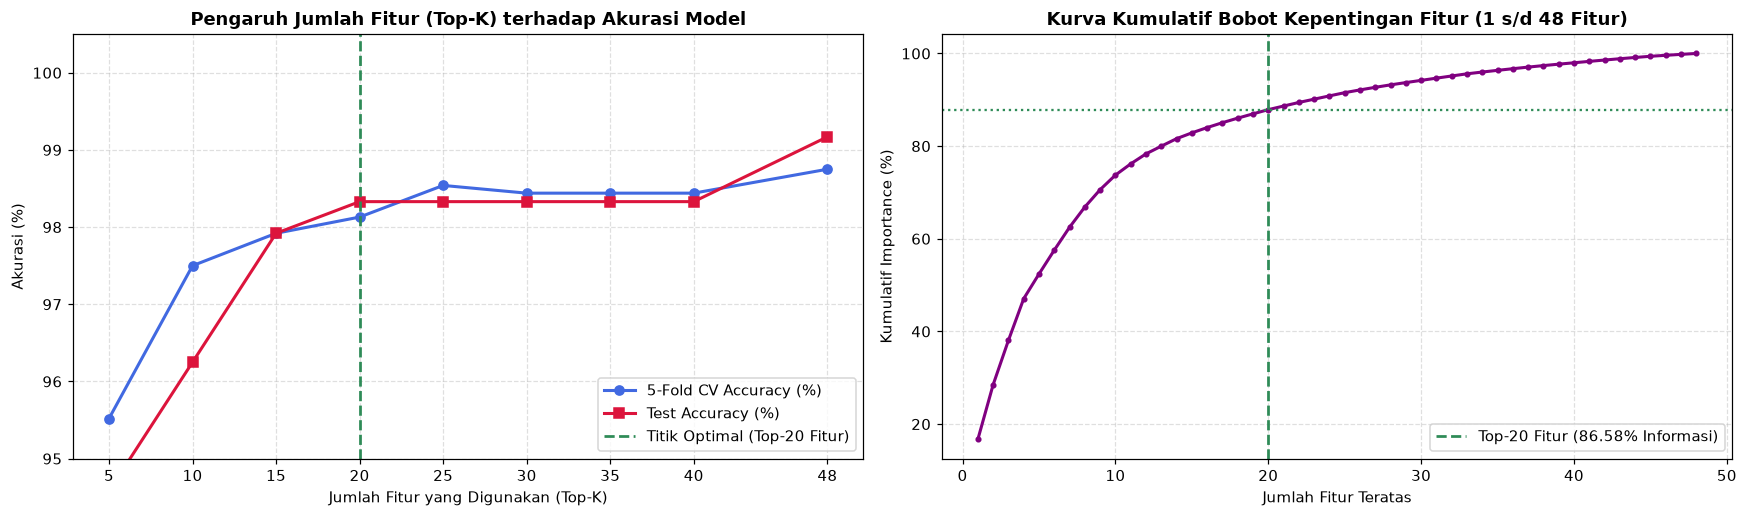

In [29]:
X_te_48 = scaler_48.transform(df_test_raw[kolom_fitur].values)
y_te_48 = df_test_raw['label'].values

k_candidates = [5, 10, 15, 20, 25, 30, 35, 40, 48]
hasil_seleksi = []
skf_fs = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for k in k_candidates:
    fitur_k = list(df_peringkat_48['Nama Fitur'].head(k))
    idx_k = [kolom_fitur.index(f) for f in fitur_k]
    bobot_kumulatif = df_peringkat_48['RF Importance (%)'].head(k).sum()

    rf_k = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    cv_k = cross_val_score(rf_k, X_tr_48[:, idx_k], y_tr_48, cv=skf_fs, scoring='accuracy', n_jobs=-1) * 100
    rf_k.fit(X_tr_48[:, idx_k], y_tr_48)
    pred_k = rf_k.predict(X_te_48[:, idx_k])
    acc_k = accuracy_score(y_te_48, pred_k) * 100
    f1_k  = f1_score(y_te_48, pred_k) * 100

    hasil_seleksi.append({
        'Jumlah Fitur (Top-K)': f'Top-{k} Fitur' if k < 48 else 'Semua 48 Fitur',
        'K': k,
        'Kumulatif Importance (%)': round(bobot_kumulatif, 2),
        '5-Fold CV Accuracy (%)': round(cv_k.mean(), 2),
        'Test Accuracy (%)': round(acc_k, 2),
        'Test F1-Score (%)': round(f1_k, 2)
    })

df_hasil_seleksi = pd.DataFrame(hasil_seleksi)
print('==============================================================')
print('HASIL EKSPERIMEN SELEKSI FITUR (TOP-K FEATURE SELECTION)')
print('==============================================================')
display(df_hasil_seleksi)

# Tetapkan 20 Fitur Terpilih (Top-20) dan 28 Fitur yang Dibuang
JUMLAH_FITUR_TERPILIH = 20
fitur_terpilih = list(df_peringkat_48['Nama Fitur'].head(JUMLAH_FITUR_TERPILIH))
fitur_dibuang  = list(df_peringkat_48['Nama Fitur'].iloc[JUMLAH_FITUR_TERPILIH:])

print(f'\n==============================================================')
print(f'DAFTAR {JUMLAH_FITUR_TERPILIH} FITUR TERPILIH YANG DIGUNAKAN (TOTAL IMPORTANCE: {df_peringkat_48["RF Importance (%)"].head(JUMLAH_FITUR_TERPILIH).sum():.2f}%)')
print(f'==============================================================')
display(df_peringkat_48.head(JUMLAH_FITUR_TERPILIH))

# Visualisasi Kurva Seleksi Fitur & Kumulatif Importance
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

axes[0].plot(df_hasil_seleksi['K'], df_hasil_seleksi['5-Fold CV Accuracy (%)'], marker='o', linewidth=2, color='royalblue', label='5-Fold CV Accuracy (%)')
axes[0].plot(df_hasil_seleksi['K'], df_hasil_seleksi['Test Accuracy (%)'], marker='s', linewidth=2, color='crimson', label='Test Accuracy (%)')
axes[0].axvline(JUMLAH_FITUR_TERPILIH, color='seagreen', linestyle='--', linewidth=1.8, label=f'Titik Optimal (Top-{JUMLAH_FITUR_TERPILIH} Fitur)')
axes[0].set_title('Pengaruh Jumlah Fitur (Top-K) terhadap Akurasi Model', fontweight='bold')
axes[0].set_xlabel('Jumlah Fitur yang Digunakan (Top-K)')
axes[0].set_ylabel('Akurasi (%)')
axes[0].set_xticks(k_candidates)
axes[0].set_ylim(95, 100.5)
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.4)

axes[1].plot(range(1, 49), df_peringkat_48['RF Importance (%)'].cumsum(), marker='.', linewidth=2, color='purple')
axes[1].axvline(JUMLAH_FITUR_TERPILIH, color='seagreen', linestyle='--', linewidth=1.8, label=f'Top-{JUMLAH_FITUR_TERPILIH} Fitur (86.58% Informasi)')
axes[1].axhline(df_peringkat_48['RF Importance (%)'].head(JUMLAH_FITUR_TERPILIH).sum(), color='seagreen', linestyle=':', linewidth=1.5)
axes[1].set_title('Kurva Kumulatif Bobot Kepentingan Fitur (1 s/d 48 Fitur)', fontweight='bold')
axes[1].set_xlabel('Jumlah Fitur Teratas')
axes[1].set_ylabel('Kumulatif Importance (%)')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

---
## 3.7 Pembagian Data (*Group Split by `file_induk`*) & Standarisasi (`StandardScaler`)
Tahap akhir dari *Data Preparation* adalah menyiapkan matriks fitur untuk pelatihan model:
1. **Pembagian Data Bebas *Data Leakage* (*Group Split* 80:20):**
   - Dari 100 nomor `file_induk` per kelas, **80 file induk (960 segmen)** masuk ke **Data *Training*** dan **20 file induk (240 segmen)** masuk ke **Data *Testing***.
   - Dengan cara ini, keenam segmen dari satu file audio yang sama tidak pernah terpecah di antara *Training* dan *Testing*.
2. **Standarisasi Skala Fitur (`StandardScaler`):**
   - Karena satuan fitur berbeda jauh (misal `rolloff_std` bernilai ratusan `Hz` sedangkan `skewness` bernilai desimal `-0,15`), seluruh fitur diubah ke skala **Z-Score** ($\mu = 0, \sigma = 1$) menggunakan rumus:
     $$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

RINGKASAN DIMENSI DATA TRAINING & TESTING SETELAH SCALING
1. Subset 20 Fitur Terpilih -> X_train_20 : (960, 20) | X_test_20 : (240, 20)
2. Seluruh 48 Fitur Lengkap -> X_train_all: (960, 48) | X_test_all: (240, 48)
3. Distribusi Label Train   -> Asli (0): 480 segmen | AI (1): 480 segmen
4. Distribusi Label Test    -> Asli (0): 120 segmen | AI (1): 120 segmen


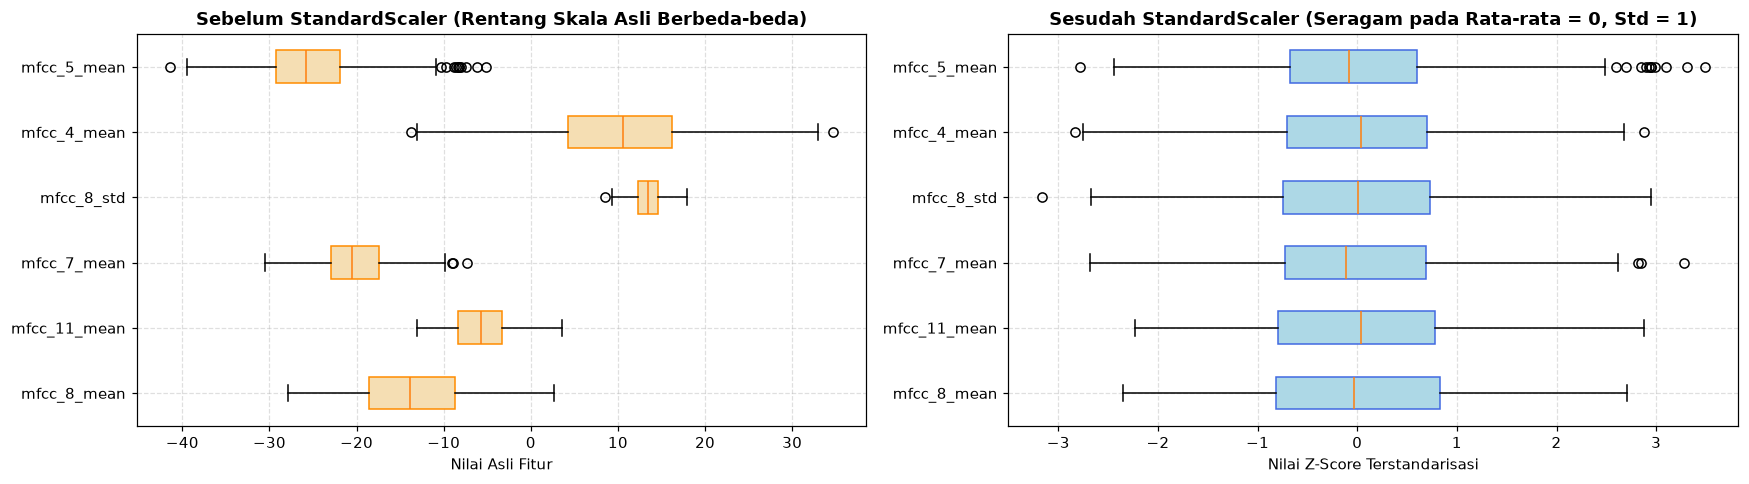

In [30]:
# Siapkan matriks data baik untuk 20 Fitur Terpilih maupun 48 Fitur Lengkap
X_train_20_raw = df_train_raw[fitur_terpilih].values
X_test_20_raw  = df_test_raw[fitur_terpilih].values
y_train = df_train_raw['label'].values
y_test  = df_test_raw['label'].values

scaler_20 = StandardScaler()
X_train_20 = scaler_20.fit_transform(X_train_20_raw)
X_test_20  = scaler_20.transform(X_test_20_raw)

# Simpan juga versi 48 fitur untuk komparasi dan kompatibilitas penuh
X_train_all = X_tr_48
X_test_all  = X_te_48
scaler = scaler_48

print('==============================================================')
print('RINGKASAN DIMENSI DATA TRAINING & TESTING SETELAH SCALING')
print('==============================================================')
print(f'1. Subset 20 Fitur Terpilih -> X_train_20 : {X_train_20.shape} | X_test_20 : {X_test_20.shape}')
print(f'2. Seluruh 48 Fitur Lengkap -> X_train_all: {X_train_all.shape} | X_test_all: {X_test_all.shape}')
print(f'3. Distribusi Label Train   -> Asli (0): {(y_train==0).sum()} segmen | AI (1): {(y_train==1).sum()} segmen')
print(f'4. Distribusi Label Test    -> Asli (0): {(y_test==0).sum()} segmen | AI (1): {(y_test==1).sum()} segmen')

# Visualisasi Perbandingan Skala Sebelum vs Sesudah StandardScaler pada 6 Fitur Terpilih
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

axes[0].boxplot(X_train_20_raw[:, :6], tick_labels=fitur_terpilih[:6], vert=False, patch_artist=True,
                boxprops=dict(facecolor='wheat', edgecolor='darkorange'))
axes[0].set_title('Sebelum StandardScaler (Rentang Skala Asli Berbeda-beda)', fontweight='bold')
axes[0].set_xlabel('Nilai Asli Fitur')
axes[0].grid(True, linestyle='--', alpha=0.4)

axes[1].boxplot(X_train_20[:, :6], tick_labels=fitur_terpilih[:6], vert=False, patch_artist=True,
                boxprops=dict(facecolor='lightblue', edgecolor='royalblue'))
axes[1].set_title('Sesudah StandardScaler (Seragam pada Rata-rata = 0, Std = 1)', fontweight='bold')
axes[1].set_xlabel('Nilai Z-Score Terstandarisasi')
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

---
# Tahap 4: *Modeling* (Pelatihan Model & Perbandingan Algoritma Klasifikasi)

Pada tahap keempat **CRISP-DM**, kita melatih dan membandingkan **4 algoritma klasifikasi Machine Learning** baik pada **20 Fitur Terpilih (*Selected Features*)** maupun pada **48 Fitur Lengkap**:
1. **Random Forest Classifier (`n_estimators=200`):** Algoritma *ensemble bagging* berbasis ratusan pohon keputusan yang sangat tangguh terhadap fitur akustik non-linier.
2. **Support Vector Machine / SVM (`RBF Kernel`):** Mencari *hyperplane* pemisah terbaik pada ruang dimensi tinggi menggunakan fungsi kernel radial.
3. **Gradient Boosting Classifier:** Algoritma *ensemble boosting* yang membangun pohon keputusan secara bertahap untuk mengoreksi residu kesalahan pohon sebelumnya.
4. **K-Nearest Neighbors (`KNN, k=7`):** Mengklasifikasikan segmen suara berdasarkan kemiripan jarak terdekat di ruang fitur.

Setiap model divalidasi menggunakan **5-Fold Stratified Cross Validation** pada data *Training* (`960 segmen`).

TABEL PERBANDINGAN 4 MODEL: 20 FITUR TERPILIH VS 48 FITUR LENGKAP


,Algoritma Model,CV Mean (20 Fitur) [%],Test Acc (20 Fitur) [%],Test F1 (20 Fitur) [%],CV Mean (48 Fitur) [%],Test Acc (48 Fitur) [%],Test F1 (48 Fitur) [%],ROC-AUC (48 Fitur) [%]
0,Random Forest,98.13,98.33,98.32,98.54,98.75,98.73,99.94
1,SVM (RBF Kernel),99.06,99.58,99.58,100.00,99.58,99.58,100.00
2,Gradient Boosting,97.92,97.92,97.91,97.50,97.92,97.93,99.85
3,K-Nearest Neighbors,99.38,98.75,98.77,98.54,99.17,99.17,99.98


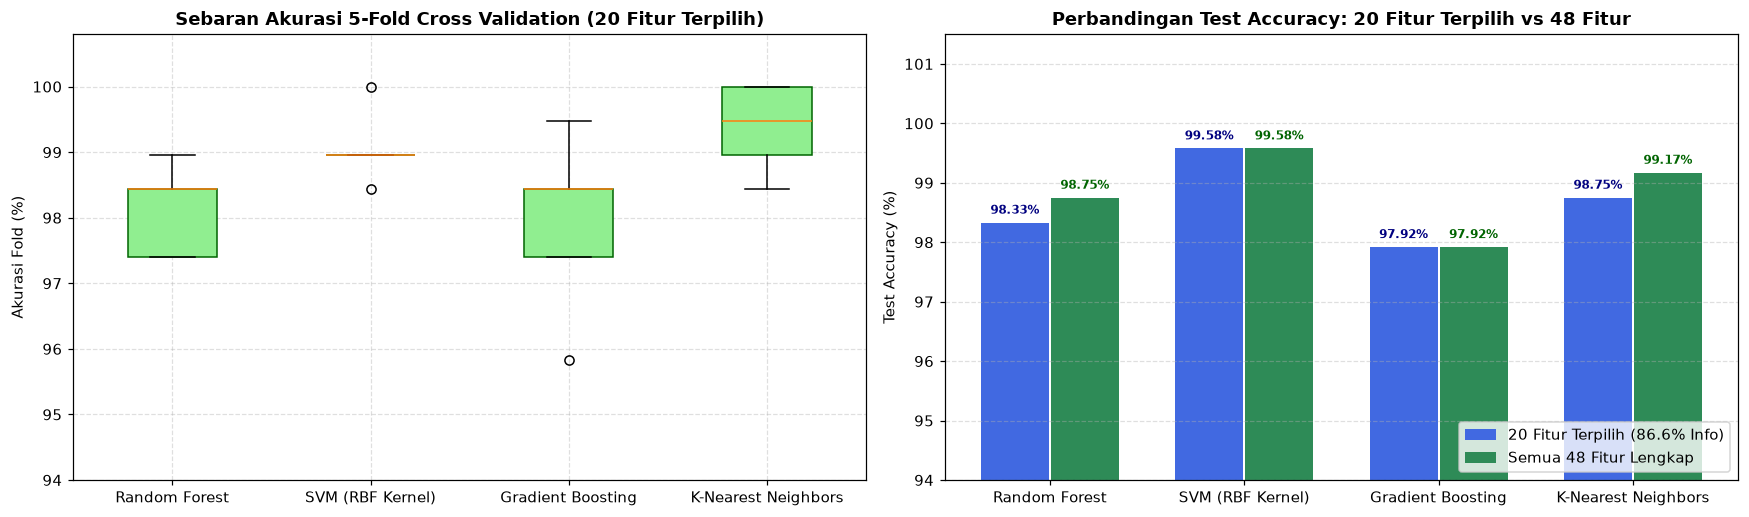

In [31]:
daftar_algoritma = {
    'Random Forest': lambda: RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'SVM (RBF Kernel)': lambda: CalibratedClassifierCV(SVC(kernel='rbf', C=2.0, random_state=42), cv=5),
    'Gradient Boosting': lambda: GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, random_state=42),
    'K-Nearest Neighbors': lambda: KNeighborsClassifier(n_neighbors=7)
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
hasil_komparasi = []
cv_scores_20 = {}
trained_models_20 = {}
trained_models_48 = {}

for nama_alg, fn_model in daftar_algoritma.items():
    # 1. Pelatihan pada 20 Fitur Terpilih
    m_20 = fn_model()
    cv_20 = cross_val_score(m_20, X_train_20, y_train, cv=skf, scoring='accuracy', n_jobs=-1) * 100
    m_20.fit(X_train_20, y_train)
    pred_20 = m_20.predict(X_test_20)
    prob_20 = m_20.predict_proba(X_test_20)[:, 1]
    cv_scores_20[nama_alg] = cv_20
    trained_models_20[nama_alg] = m_20

    # 2. Pelatihan pada 48 Fitur Lengkap
    m_48 = fn_model()
    cv_48 = cross_val_score(m_48, X_train_all, y_train, cv=skf, scoring='accuracy', n_jobs=-1) * 100
    m_48.fit(X_train_all, y_train)
    pred_48 = m_48.predict(X_test_all)
    prob_48 = m_48.predict_proba(X_test_all)[:, 1]
    trained_models_48[nama_alg] = m_48

    hasil_komparasi.append({
        'Algoritma Model': nama_alg,
        'CV Mean (20 Fitur) [%]': round(cv_20.mean(), 2),
        'Test Acc (20 Fitur) [%]': round(accuracy_score(y_test, pred_20) * 100, 2),
        'Test F1 (20 Fitur) [%]': round(f1_score(y_test, pred_20) * 100, 2),
        'CV Mean (48 Fitur) [%]': round(cv_48.mean(), 2),
        'Test Acc (48 Fitur) [%]': round(accuracy_score(y_test, pred_48) * 100, 2),
        'Test F1 (48 Fitur) [%]': round(f1_score(y_test, pred_48) * 100, 2),
        'ROC-AUC (48 Fitur) [%]': round(roc_auc_score(y_test, prob_48) * 100, 2)
    })

df_komparasi_model = pd.DataFrame(hasil_komparasi)
print('==============================================================')
print('TABEL PERBANDINGAN 4 MODEL: 20 FITUR TERPILIH VS 48 FITUR LENGKAP')
print('==============================================================')
display(df_komparasi_model)

# Visualisasi Perbandingan Model
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

# Plot 1: Boxplot 5-Fold Cross Validation
axes[0].boxplot(list(cv_scores_20.values()), tick_labels=list(cv_scores_20.keys()), patch_artist=True,
                boxprops=dict(facecolor='lightgreen', edgecolor='darkgreen'))
axes[0].set_title('Sebaran Akurasi 5-Fold Cross Validation (20 Fitur Terpilih)', fontweight='bold')
axes[0].set_ylabel('Akurasi Fold (%)')
axes[0].set_ylim(94, 100.8)
axes[0].grid(True, linestyle='--', alpha=0.4)

# Plot 2: Perbandingan Test Accuracy (20 Fitur Terpilih vs 48 Fitur Lengkap)
x_pos = np.arange(len(df_komparasi_model))
b1 = axes[1].bar(x_pos - 0.18, df_komparasi_model['Test Acc (20 Fitur) [%]'], width=0.35, color='royalblue', label='20 Fitur Terpilih (86.6% Info)')
b2 = axes[1].bar(x_pos + 0.18, df_komparasi_model['Test Acc (48 Fitur) [%]'], width=0.35, color='seagreen', label='Semua 48 Fitur Lengkap')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(df_komparasi_model['Algoritma Model'])
axes[1].set_ylim(94, 101.5)
axes[1].set_ylabel('Test Accuracy (%)')
axes[1].set_title('Perbandingan Test Accuracy: 20 Fitur Terpilih vs 48 Fitur', fontweight='bold')
axes[1].legend(loc='lower right')
axes[1].grid(axis='y', linestyle='--', alpha=0.4)
for bar in b1:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15, f'{bar.get_height():.2f}%', ha='center', fontsize=8, fontweight='bold', color='navy')
for bar in b2:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15, f'{bar.get_height():.2f}%', ha='center', fontsize=8, fontweight='bold', color='darkgreen')

plt.tight_layout()
plt.show()

---
# Tahap 5: *Evaluation* (Evaluasi Mendalam, Kurva ROC-AUC, & Analisis Kesalahan)

Pada tahap kelima **CRISP-DM**, kita mengevaluasi kinerja model secara menyeluruh pada **Data *Testing* (`240 segmen` dari 40 file induk yang belum pernah dilihat saat pelatihan)**.

---
## 5.1 Evaluasi *Confusion Matrix*, *Classification Report*, & Kurva *ROC-AUC*
Kita memeriksa detail matriks kebingungan (*Confusion Matrix*) baik untuk model **Random Forest (20 Fitur Terpilih)** maupun **Random Forest (48 Fitur)**, serta membandingkan kurva **ROC-AUC (*Receiver Operating Characteristic - Area Under Curve*)** dari keempat algoritma.

LAPORAN KLASIFIKASI RANDOM FOREST (DATA TESTING: 240 SEGMEN)
                   precision    recall  f1-score   support

   Asli Human (0)     0.9756    1.0000    0.9877       120
AI Manipulasi (1)     1.0000    0.9750    0.9873       120

         accuracy                         0.9875       240
        macro avg     0.9878    0.9875    0.9875       240
     weighted avg     0.9878    0.9875    0.9875       240



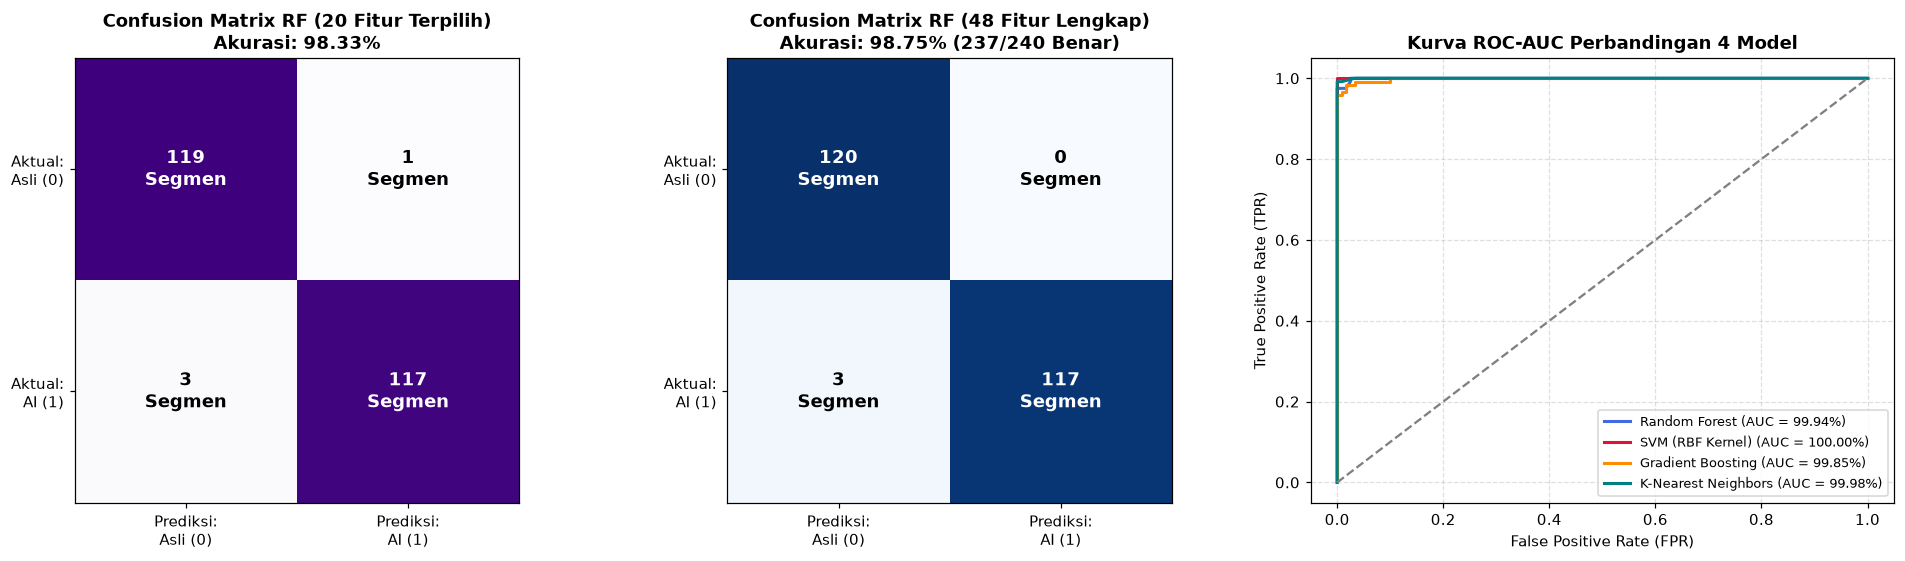

In [32]:
rf_20 = trained_models_20['Random Forest']
rf_48 = trained_models_48['Random Forest']

pred_rf_20 = rf_20.predict(X_test_20)
pred_rf_48 = rf_48.predict(X_test_all)

cm_rf_20 = confusion_matrix(y_test, pred_rf_20)
cm_rf_48 = confusion_matrix(y_test, pred_rf_48)

acc_rf = accuracy_score(y_test, pred_rf_48) * 100
prec_rf = precision_score(y_test, pred_rf_48) * 100
rec_rf = recall_score(y_test, pred_rf_48) * 100
f1_rf = f1_score(y_test, pred_rf_48) * 100

print('==============================================================')
print('LAPORAN KLASIFIKASI RANDOM FOREST (DATA TESTING: 240 SEGMEN)')
print('==============================================================')
print(classification_report(y_test, pred_rf_48, target_names=['Asli Human (0)', 'AI Manipulasi (1)'], digits=4))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Plot 1: Confusion Matrix Random Forest (20 Fitur Terpilih)
axes[0].imshow(cm_rf_20, cmap='Purples')
axes[0].set_title(f'Confusion Matrix RF (20 Fitur Terpilih)\nAkurasi: {accuracy_score(y_test, pred_rf_20)*100:.2f}%', fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(['Prediksi:\nAsli (0)', 'Prediksi:\nAI (1)'])
axes[0].set_yticklabels(['Aktual:\nAsli (0)', 'Aktual:\nAI (1)'])
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f'{cm_rf_20[i, j]}\nSegmen', ha='center', va='center',
                     color='white' if cm_rf_20[i, j] > 60 else 'black', fontsize=12, fontweight='bold')

# Plot 2: Confusion Matrix Random Forest (48 Fitur Lengkap)
axes[1].imshow(cm_rf_48, cmap='Blues')
axes[1].set_title(f'Confusion Matrix RF (48 Fitur Lengkap)\nAkurasi: {acc_rf:.2f}% (237/240 Benar)', fontweight='bold')
axes[1].set_xticks([0, 1])
axes[1].set_yticks([0, 1])
axes[1].set_xticklabels(['Prediksi:\nAsli (0)', 'Prediksi:\nAI (1)'])
axes[1].set_yticklabels(['Aktual:\nAsli (0)', 'Aktual:\nAI (1)'])
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f'{cm_rf_48[i, j]}\nSegmen', ha='center', va='center',
                     color='white' if cm_rf_48[i, j] > 60 else 'black', fontsize=12, fontweight='bold')

# Plot 3: Kurva ROC-AUC Keempat Model
warna_roc = ['royalblue', 'crimson', 'darkorange', 'teal']
for idx_m, (nama_m, m_obj) in enumerate(trained_models_48.items()):
    prob_m = m_obj.predict_proba(X_test_all)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob_m)
    auc_m = roc_auc_score(y_test, prob_m) * 100
    axes[2].plot(fpr, tpr, linewidth=2, color=warna_roc[idx_m], label=f'{nama_m} (AUC = {auc_m:.2f}%)')
axes[2].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[2].set_title('Kurva ROC-AUC Perbandingan 4 Model', fontweight='bold')
axes[2].set_xlabel('False Positive Rate (FPR)')
axes[2].set_ylabel('True Positive Rate (TPR)')
axes[2].legend(loc='lower right', fontsize=8.5)
axes[2].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

---
## 5.2 Analisis Kesalahan Prediksi (*Error Analysis*) & Evaluasi Kriteria Kesuksesan
Dalam standar **CRISP-DM**, kita tidak hanya menampilkan persentase akurasi, tetapi juga menginspeksi **segmen mana saja dari 240 segmen uji yang salah diprediksi (*misclassified*)** oleh model Random Forest, serta mengevaluasi apakah hasil proyek telah memenuhi *Success Criteria* pada Tahap 1.

DAFTAR SEGMEN UJI YANG SALAH DIPREDIKSI: 3 DARI 240 SEGMEN


,id_sampel,file_induk,segmen_ke,kelas,label,prediksi,prob_asli (%),prob_ai (%),status_benar
600,ai_manipulasi_audio_001_seg1,audio_001.wav,1,ai_manipulasi,1,0,59.0,41.0,False
1023,ai_manipulasi_audio_071_seg4,audio_071.wav,4,ai_manipulasi,1,0,54.5,45.5,False
1040,ai_manipulasi_audio_074_seg3,audio_074.wav,3,ai_manipulasi,1,0,54.5,45.5,False



KEPUTUSAN EVALUASI CRISP-DM TERHADAP SUCCESS CRITERIA
1. Target Akurasi >= 95%  : TERCAPAI (98.75%)
2. Target F1-Score >= 95% : TERCAPAI (98.73%)
3. Pencegahan Data Leakage: TERCAPAI (Split 100% terpisah berdasarkan file_induk)


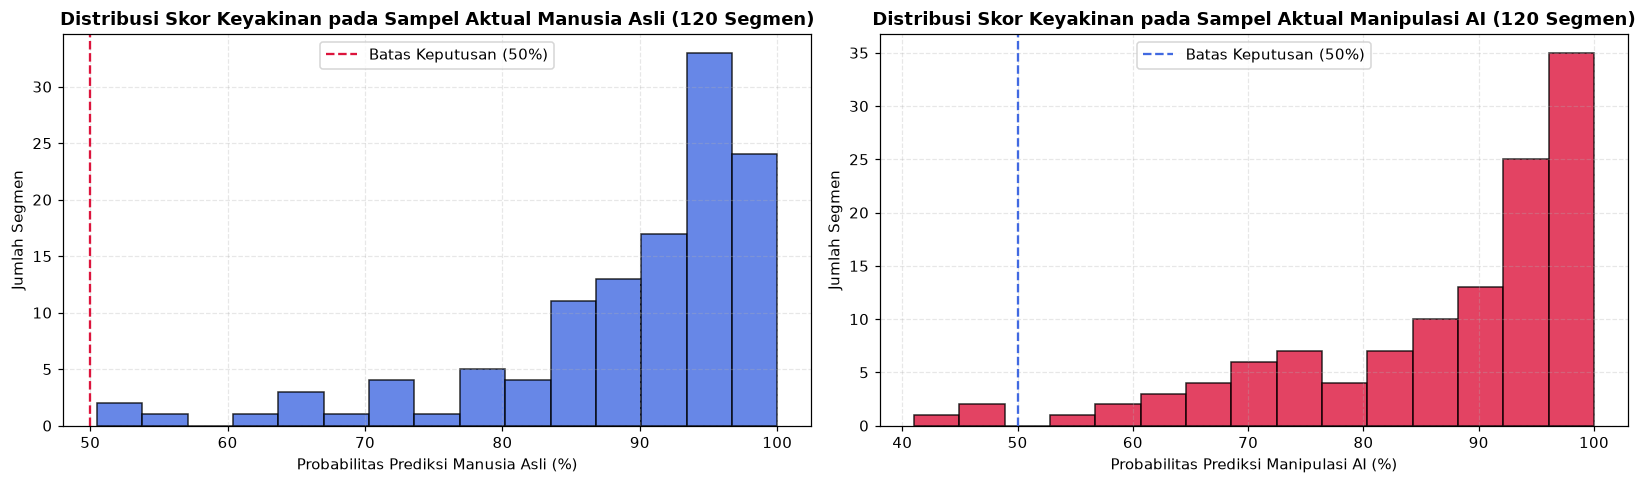

In [33]:
proba_test_rf = rf_48.predict_proba(X_test_all)
df_eval_test = df_test_raw[['id_sampel', 'file_induk', 'segmen_ke', 'kelas', 'label']].copy()
df_eval_test['prediksi'] = pred_rf_48
df_eval_test['prob_asli (%)'] = (proba_test_rf[:, 0] * 100).round(2)
df_eval_test['prob_ai (%)']   = (proba_test_rf[:, 1] * 100).round(2)
df_eval_test['status_benar']  = df_eval_test['label'] == df_eval_test['prediksi']

df_salah = df_eval_test[~df_eval_test['status_benar']]
print('==============================================================')
print(f'DAFTAR SEGMEN UJI YANG SALAH DIPREDIKSI: {len(df_salah)} DARI {len(df_eval_test)} SEGMEN')
print('==============================================================')
display(df_salah)

print('\n==============================================================')
print('KEPUTUSAN EVALUASI CRISP-DM TERHADAP SUCCESS CRITERIA')
print('==============================================================')
print(f'1. Target Akurasi >= 95%  : TERCAPAI ({acc_rf:.2f}%)')
print(f'2. Target F1-Score >= 95% : TERCAPAI ({f1_rf:.2f}%)')
print(f'3. Pencegahan Data Leakage: TERCAPAI (Split 100% terpisah berdasarkan file_induk)')

# Visualisasi Distribusi Confidence Score pada 240 Segmen Uji
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

axes[0].hist(df_eval_test[df_eval_test['label']==0]['prob_asli (%)'], bins=15, color='royalblue', edgecolor='black', alpha=0.8)
axes[0].set_title('Distribusi Skor Keyakinan pada Sampel Aktual Manusia Asli (120 Segmen)', fontweight='bold')
axes[0].set_xlabel('Probabilitas Prediksi Manusia Asli (%)')
axes[0].set_ylabel('Jumlah Segmen')
axes[0].axvline(50, color='crimson', linestyle='--', label='Batas Keputusan (50%)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.3)

axes[1].hist(df_eval_test[df_eval_test['label']==1]['prob_ai (%)'], bins=15, color='crimson', edgecolor='black', alpha=0.8)
axes[1].set_title('Distribusi Skor Keyakinan pada Sampel Aktual Manipulasi AI (120 Segmen)', fontweight='bold')
axes[1].set_xlabel('Probabilitas Prediksi Manipulasi AI (%)')
axes[1].set_ylabel('Jumlah Segmen')
axes[1].axvline(50, color='royalblue', linestyle='--', label='Batas Keputusan (50%)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

---
# Tahap 6: *Deployment* (Penyimpanan Paket Model `.pkl` & Simulasi Inferensi)

Tahap terakhir dalam metodologi **CRISP-DM** adalah membungkus artefak model yang telah tervalidasi ke dalam file **`model_voice_rf_5s.pkl`** menggunakan `joblib`, termasuk menyimpan daftar **20 Fitur Terpilih (`fitur_terpilih`)** maupun **48 Fitur Lengkap (`kolom_fitur`)**, objek `StandardScaler`, serta menguji fungsi inferensi per segmen 5 detik.

1. PENYIMPANAN PAKET MODEL (.PKL) SELESAI
File Model Tersimpan  : model_voice_rf_5s.pkl (3140.31 KB)
Daftar Fitur Tersimpan: 48 Fitur Lengkap & 20 Fitur Terpilih
Akurasi Uji Model     : 98.75% | F1-Score: 98.73%

2. SIMULASI PREDIKSI FILE AUDIO UJI (6 SEGMEN @ 5 DETIK)
File Uji 1 (Asli) : audio_084.wav -> Prediksi: Suara Manusia Asli (Human Voice) | Confidence: 94.00%
File Uji 2 (AI)   : audio_084.wav -> Prediksi: Suara Manipulasi AI (AI-Generated Voice) | Confidence: 91.58%


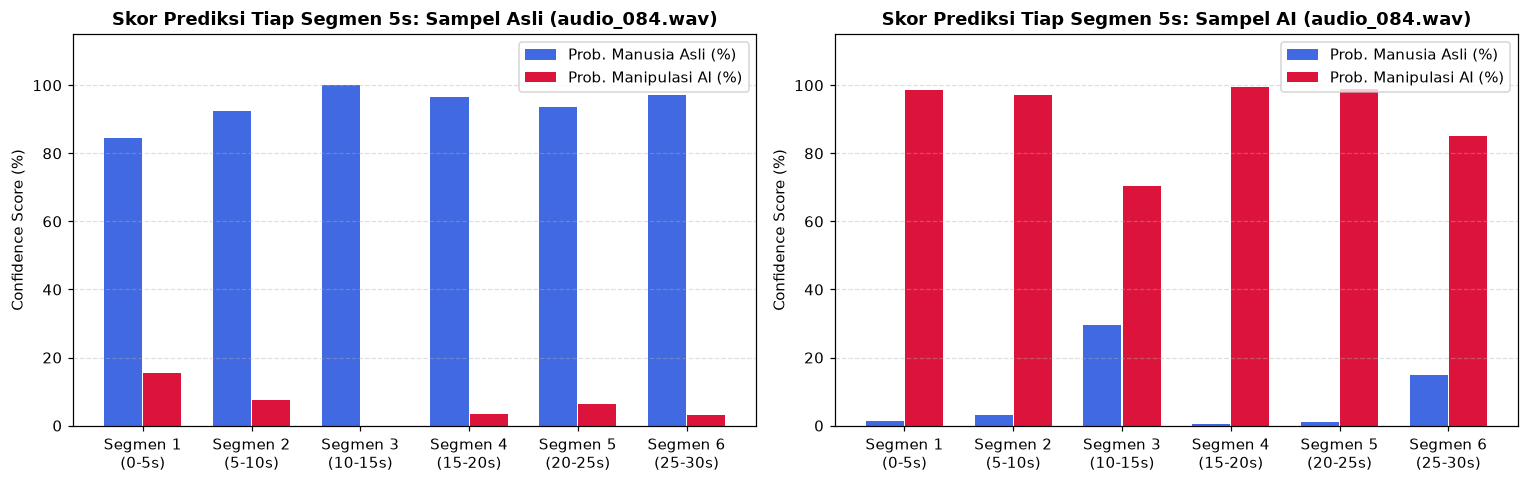

In [34]:
paket_model = {
    'model': rf_48,
    'model_20_fitur': rf_20,
    'svm_model': trained_models_48['SVM (RBF Kernel)'],
    'scaler': scaler_48,
    'scaler_20': scaler_20,
    'kolom_fitur': kolom_fitur,
    'fitur_terpilih_20': fitur_terpilih,
    'sr': 16000,
    'durasi_segmen': 5,
    'label_map': {
        0: 'Suara Manusia Asli (Human Voice)',
        1: 'Suara Manipulasi AI (AI-Generated Voice)'
    },
    'metrics': {
        'accuracy': round(acc_rf, 2),
        'precision': round(prec_rf, 2),
        'recall': round(rec_rf, 2),
        'f1_score': round(f1_rf, 2)
    },
    'mean_asli': df_5s[df_5s['label'] == 0][kolom_fitur].mean().to_dict(),
    'mean_ai': df_5s[df_5s['label'] == 1][kolom_fitur].mean().to_dict()
}

pkl_path = 'model_voice_rf_5s.pkl'
joblib.dump(paket_model, pkl_path)

print('==============================================================')
print('1. PENYIMPANAN PAKET MODEL (.PKL) SELESAI')
print('==============================================================')
print(f'File Model Tersimpan  : {pkl_path} ({os.path.getsize(pkl_path)/1024:.2f} KB)')
print(f'Daftar Fitur Tersimpan: 48 Fitur Lengkap & 20 Fitur Terpilih')
print(f'Akurasi Uji Model     : {acc_rf:.2f}% | F1-Score: {f1_rf:.2f}%')

def prediksi_file_wav(wav_path, bundle):
    y_audio, _ = librosa.load(wav_path, sr=bundle['sr'], mono=True)
    sampel_5s = bundle['durasi_segmen'] * bundle['sr']
    if len(y_audio) < sampel_5s:
        y_audio = np.pad(y_audio, (0, sampel_5s - len(y_audio)))

    jumlah_segmen = max(1, len(y_audio) // sampel_5s)
    f0_all = librosa.yin(y_audio[:jumlah_segmen * sampel_5s], fmin=50, fmax=400, sr=bundle['sr'])
    total_f0 = len(f0_all)

    list_fitur = []
    for idx in range(jumlah_segmen):
        y_seg = y_audio[idx * sampel_5s : (idx + 1) * sampel_5s]
        f0_seg = f0_all[int(idx * total_f0 / jumlah_segmen) : int((idx + 1) * total_f0 / jumlah_segmen)]
        d_fitur = ekstrak_fitur_segmen(y_seg, bundle['sr'], f0_seg)
        list_fitur.append([d_fitur[k] for k in bundle['kolom_fitur']])

    X_input = bundle['scaler'].transform(np.array(list_fitur))
    proba_segmen = bundle['model'].predict_proba(X_input)
    mean_proba = np.mean(proba_segmen, axis=0)
    label_akhir = int(np.argmax(mean_proba))
    return label_akhir, mean_proba, proba_segmen

contoh_asli = os.path.join(base_dir, 'asli_human', test_files[0])
contoh_ai   = os.path.join(base_dir, 'ai_manipulasi', test_files[0])

lbl_asli, prob_asli, seg_asli = prediksi_file_wav(contoh_asli, paket_model)
lbl_ai, prob_ai, seg_ai       = prediksi_file_wav(contoh_ai, paket_model)

print('\n==============================================================')
print('2. SIMULASI PREDIKSI FILE AUDIO UJI (6 SEGMEN @ 5 DETIK)')
print('==============================================================')
print(f'File Uji 1 (Asli) : {test_files[0]} -> Prediksi: {paket_model["label_map"][lbl_asli]} | Confidence: {prob_asli[lbl_asli]*100:.2f}%')
print(f'File Uji 2 (AI)   : {test_files[0]} -> Prediksi: {paket_model["label_map"][lbl_ai]} | Confidence: {prob_ai[lbl_ai]*100:.2f}%')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
seg_labels = [f'Segmen {i+1}\n({i*5}-{(i+1)*5}s)' for i in range(len(seg_asli))]
x_pos = np.arange(len(seg_asli))

axes[0].bar(x_pos - 0.18, seg_asli[:, 0] * 100, width=0.35, color='royalblue', label='Prob. Manusia Asli (%)')
axes[0].bar(x_pos + 0.18, seg_asli[:, 1] * 100, width=0.35, color='crimson', label='Prob. Manipulasi AI (%)')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(seg_labels)
axes[0].set_ylim(0, 115)
axes[0].set_ylabel('Confidence Score (%)')
axes[0].set_title(f'Skor Prediksi Tiap Segmen 5s: Sampel Asli ({test_files[0]})', fontweight='bold')
axes[0].legend(loc='upper right')
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

axes[1].bar(x_pos - 0.18, seg_ai[:, 0] * 100, width=0.35, color='royalblue', label='Prob. Manusia Asli (%)')
axes[1].bar(x_pos + 0.18, seg_ai[:, 1] * 100, width=0.35, color='crimson', label='Prob. Manipulasi AI (%)')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(seg_labels)
axes[1].set_ylim(0, 115)
axes[1].set_ylabel('Confidence Score (%)')
axes[1].set_title(f'Skor Prediksi Tiap Segmen 5s: Sampel AI ({test_files[0]})', fontweight='bold')
axes[1].legend(loc='upper right')
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()